In [ ]:

import os, re, json, random, collections
import numpy as np, cv2, torch, torch.nn as nn, torch.optim as optim
from pathlib import Path
from datetime import datetime
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             confusion_matrix, classification_report)

DATA_ROOT   = Path("/content/drive/MyDrive/spoof_dataset/full")
REAL_DIR    = DATA_ROOT / "real"
SPOOF_DIR   = DATA_ROOT / "spoof>>>"                 # corrected labels
PHASE1_CKPT = Path("/content/drive/MyDrive/checkpoints/best_model.pth")   # face model, 3-ch, plain state_dict

N_REAL = 550          # real images kept in the WHOLE dataset (spoof is never reduced)
assert SPOOF_DIR.name == "spoof>>>", f"Wrong spoof folder: {SPOOF_DIR}"
GLOBAL_SIZE   = 320        # full frame, letterboxed (aspect kept): bezel / hands / phone
PATCH         = 256        # native-resolution moire window (NO resizing before FFT)
SPEC          = 128        # spectrum map size fed to the moire CNN
N_TRAIN_PATCH = 4          # random patches per image in training
GRID          = 3          # 3x3 = 9 patches per image at eval/inference
BATCH, EPOCHS, PATIENCE = 16, 30, 7
UNFREEZE_AT   = 8          # epoch to unfreeze conv4-conv5 (None = keep frozen)
APCER_TARGET  = 0.05       # threshold rule (chosen on validation)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "Runtime > Change runtime type > T4 GPU"
EXTS = {".jpg", ".jpeg", ".png", ".webp"}
print("Run dir:", RUN_DIR)

NameError: name 'RUN_DIR' is not defined

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
    def list_imgs(d): return sorted(p for p in d.iterdir() if p.suffix.lower() in EXTS)
LOG_RE = re.compile(r"^(?P<log>.+)_(checkin|checkout)$", re.IGNORECASE)
def log_of(p):
    m = LOG_RE.match(Path(p).stem); return m["log"] if m else Path(p).stem

real_all  = [str(p) for p in list_imgs(REAL_DIR)]
spoof_all = [str(p) for p in list_imgs(SPOOF_DIR)]
print(f"Found: real={len(real_all)}  spoof={len(spoof_all)}  (spoof folder: {SPOOF_DIR.name})")
assert len(spoof_all) == 313, f"Expected 313 spoof>>> images, found {len(spoof_all)}"

N_REAL = 350   # ---- Downsample REAL to N_REAL, keeping checkin/checkout of the same log together ----
by_log = collections.defaultdict(list)
for p in real_all:
    by_log[log_of(p)].append(p)
logs = sorted(by_log); random.Random(SEED).shuffle(logs)
real_keep = []
for lg in logs:
    if len(real_keep) >= N_REAL: break
    real_keep.extend(by_log[lg])
real_keep = real_keep[:N_REAL]

items  = [(p, 0) for p in real_keep] + [(p, 1) for p in spoof_all]      # ALL spoofs kept
labels = np.array([y for _, y in items]); groups = np.array([log_of(p) for p, _ in items])
print(f"Dataset used: real={len(real_keep)}  spoof={len(spoof_all)}  total={len(items)}  "
      f"(ratio {len(real_keep)/len(spoof_all):.2f} : 1)")

# ---- Grouped + stratified split 70 / 15 / 15 ----
idx = np.arange(len(items))
rest, test = next(StratifiedGroupKFold(7, shuffle=True, random_state=SEED).split(idx, labels, groups))
tr_r, va_r = next(StratifiedGroupKFold(6, shuffle=True, random_state=SEED).split(rest, labels[rest], groups[rest]))
train, val = rest[tr_r], rest[va_r]
for a, b in [(train, val), (train, test), (val, test)]:
    assert set(groups[a]).isdisjoint(groups[b]), "GROUP LEAKAGE"

splits = {"train": [items[i] for i in train], "val": [items[i] for i in val], "test": [items[i] for i in test]}
for k, v in splits.items():
    c = collections.Counter(y for _, y in v); print(f"{k:5s}: real={c[0]:4d} spoof={c[1]:4d}")
assert sum(collections.Counter(y for _, y in v)[1] for v in splits.values()) == 313, "spoof count changed!"
assert all(collections.Counter(y for _, y in splits[s])[1] >= 15 for s in ["val", "test"])

Found: real=4879  spoof=313  (spoof folder: spoof>>>)
Dataset used: real=350  spoof=313  total=663  (ratio 1.12 : 1)
train: real= 253 spoof= 223
val  : real=  48 spoof=  45
test : real=  49 spoof=  45


In [ ]:
# ===== NEW 1b. LEAKAGE AUDIT — run BEFORE training (read-only) =====
import hashlib, pandas as pd
def norm_stem(p):
    s = Path(p).stem
    s = re.sub(r"^copy of\s+", "", s, flags=re.I); s = re.sub(r"\s*\(\d+\)$", "", s)
    s = re.sub(r"\.(jpe?g|joeg|png|webp)$", "", s, flags=re.I)
    return s.strip().lower()

def group_v2(p):
    """Stricter group key: strips 'Copy of'/'(1)', joins a spoof with the real image of the same punch log,
    and treats N_M names as session N (session meaning = hypothesis, confirm with whoever collected the data)."""
    s = norm_stem(p); m = LOG_RE.match(s)
    if m: return "log:" + m["log"]
    m = re.match(r"^(\d+)_\d+$", s)
    return ("sess:" + m[1]) if m else ("file:" + s)

def md5(p):
    with open(p, "rb") as f: return hashlib.md5(f.read()).hexdigest()

split_of = {p: k for k, v in splits.items() for p, _ in v}
AUD = pd.DataFrame([{"file": Path(p).name, "path": p, "label": y, "split": split_of[p],
                     "stem": norm_stem(p), "g2": group_v2(p)} for p, y in items])
AUD["md5"] = [md5(p) for p in tqdm(AUD.path, desc="hashing")]
LEAK = {}
for key in ["md5", "stem", "g2"]:
    g = AUD.groupby(key).agg(n_splits=("split", "nunique"), n_labels=("label", "nunique"),
                             splits_=("split", lambda s: sorted(set(s))), files=("file", list))
    LEAK[key] = int((g.n_splits > 1).sum())
    print(f"[{key:4s}] groups crossing splits: {LEAK[key]:3d} | groups containing real AND spoof: {int((g.n_labels > 1).sum())}")
    bad_ = g[(g.n_splits > 1) | (g.n_labels > 1)]
    if len(bad_): display(bad_.head(10))
print("\nLEAK =", LEAK)

hashing:   0%|          | 0/663 [00:00<?, ?it/s]

[md5 ] groups crossing splits:   2 | groups containing real AND spoof: 0


,n_splits,n_labels,splits_,files
md5,,,,
24e88d4ad866c284cf25b40e20895a2c,2,1,"[test, train]","[21_2.jpg, 4_2.jpg]"
a38a7398ddbbee5d0ec9107bd071dc44,2,1,"[test, train]","[2_2.jpeg, 57_2.jpeg]"


[stem] groups crossing splits:   7 | groups containing real AND spoof: 0


,n_splits,n_labels,splits_,files
stem,,,,
0_3,2,1,"[test, train]","[Copy of 0_3(1).jpeg, Copy of 0_3.jpeg]"
11_2,2,1,"[train, val]","[11_2.jpeg, Copy of 11_2.jpeg]"
25_3,2,1,"[test, train]","[25_3.jpg, Copy of 25_3.jpeg]"
2_2,2,1,"[test, train]","[2_2.jpeg, Copy of 2_2.jpeg]"
40_2,2,1,"[test, train]","[40_2.jpeg, Copy of 40_2.jpeg]"
45_3,2,1,"[train, val]","[45_3.jpg, Copy of 45_3.jpeg]"
68_2,2,1,"[train, val]","[68_2.jpg, Copy of 68_2.jpeg]"


[g2  ] groups crossing splits:  22 | groups containing real AND spoof: 14


,n_splits,n_labels,splits_,files
g2,,,,
log:6ac761212a92dc79eab63877,1,2,[val],"[6ac761212a92dc79eab63877_checkout.jpg, Copy o..."
log:6ac7a7bc0b3f3550e3313e8f,2,2,"[train, val]","[6ac7a7bc0b3f3550e3313e8f_checkout.jpg, Copy o..."
log:6ac7bceb2a92dc79eab64a3c,1,2,[train],"[6ac7bceb2a92dc79eab64a3c_checkout.jpg, Copy o..."
log:6ac7cff99453982821976e11,2,2,"[test, train]","[6ac7cff99453982821976e11_checkout.jpg, Copy o..."
log:6ac7d32475c9a02de55df193,2,2,"[test, train]","[6ac7d32475c9a02de55df193_checkout.jpg, Copy o..."
log:6ac7df19c55d39617f30907b,1,2,[train],"[6ac7df19c55d39617f30907b_checkout.jpg, Copy o..."
log:6ac8fa80464fc55e44274226,1,2,[train],"[6ac8fa80464fc55e44274226_checkout.jpg, Copy o..."
log:6ac8fd73be00ad6709810b17,1,2,[train],"[6ac8fd73be00ad6709810b17_checkout.jpg, Copy o..."
log:6ac8fd9abe00ad6709810b1f,2,2,"[test, train]","[6ac8fd9abe00ad6709810b1f_checkout.jpg, Copy o..."



LEAK = {'md5': 2, 'stem': 7, 'g2': 22}


In [ ]:
# ===== NEW 1c. SPLIT DECISION =====
USE_STRICT_SPLIT = sum(LEAK.values()) > 0          # set False to force the original split
if USE_STRICT_SPLIT:
    seen, items2 = set(), []
    for (p, y), h in zip(items, AUD.md5):
        if h in seen: continue
        seen.add(h); items2.append((p, y))
    lab2 = np.array([y for _, y in items2]); grp2 = np.array([group_v2(p) for p, _ in items2]); ix2 = np.arange(len(items2))
    rest, test = next(StratifiedGroupKFold(7, shuffle=True, random_state=SEED).split(ix2, lab2, grp2))
    tr_r, va_r = next(StratifiedGroupKFold(6, shuffle=True, random_state=SEED).split(rest, lab2[rest], grp2[rest]))
    train, val = rest[tr_r], rest[va_r]
    for a, b in [(train, val), (train, test), (val, test)]:
        assert set(grp2[a]).isdisjoint(grp2[b]), "GROUP LEAKAGE"
    splits = {"train": [items2[i] for i in train], "val": [items2[i] for i in val], "test": [items2[i] for i in test]}
    print(f"STRICT split used ({len(items) - len(items2)} exact duplicates removed):")
else:
    print("Original split kept:")
for k, v in splits.items():
    c = collections.Counter(y for _, y in v); print(f"  {k:5s}: real={c[0]:4d} spoof={c[1]:4d}")
json.dump({"strict": bool(USE_STRICT_SPLIT), **{k: [[Path(p).name, int(y)] for p, y in v] for k, v in splits.items()}},
          open(RUN_DIR / "splits_phase1.json", "w"), indent=1)
print("split manifest saved ->", RUN_DIR / "splits_phase1.json")

STRICT split used (3 exact duplicates removed):
  train: real= 245 spoof= 226
  val  : real=  50 spoof=  43
  test : real=  55 spoof=  41
split manifest saved -> /content/drive/MyDrive/checkpoints_fullframe_moire/run_20261026_061459/splits_phase1.json


In [ ]:
def load_bgr(path):
    with Image.open(path) as im:
        return cv2.cvtColor(np.asarray(ImageOps.exif_transpose(im).convert("RGB")), cv2.COLOR_RGB2BGR)

def letterbox(img, size):
    h, w = img.shape[:2]; s = size / max(h, w)
    r = cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    c = np.zeros((size, size, 3), np.uint8); y0, x0 = (size - r.shape[0]) // 2, (size - r.shape[1]) // 2
    c[y0:y0 + r.shape[0], x0:x0 + r.shape[1]] = r
    return c

def random_zoom(img, lo=0.6, hi=1.6):              # breaks the face-size shortcut (global branch only)
    s = np.random.uniform(lo, hi); h, w = img.shape[:2]
    if s >= 1:
        ch, cw = int(h / s), int(w / s); y0, x0 = np.random.randint(0, h - ch + 1), np.random.randint(0, w - cw + 1)
        return img[y0:y0 + ch, x0:x0 + cw]
    ph, pw = int(h * (1 / s - 1) / 2), int(w * (1 / s - 1) / 2)
    return cv2.copyMakeBorder(img, ph, ph, pw, pw, cv2.BORDER_REFLECT)

_HANN = {}
def spectrum(gray_patch):
    """log-magnitude FFT of a NATIVE-resolution patch -> z-scored SPEC x SPEC map."""
    P = gray_patch.shape[0]
    if P not in _HANN: _HANN[P] = np.outer(np.hanning(P), np.hanning(P)).astype(np.float32)
    g = gray_patch.astype(np.float32); g -= g.mean()
    S = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g * _HANN[P]))))
    if P != SPEC: S = cv2.resize(S, (SPEC, SPEC), interpolation=cv2.INTER_AREA)  # resizes the SPECTRUM, not the image
    return ((S - S.mean()) / (S.std() + 1e-6)).astype(np.float32)

def native_patches(gray, train):
    h, w = gray.shape; P = min(PATCH, h, w)           # small frames: smaller native window, never upscaled
    if train:
        ys = np.clip(np.random.normal((h - P) / 2, (h - P) / 4 + 1, N_TRAIN_PATCH), 0, h - P).astype(int)
        xs = np.clip(np.random.normal((w - P) / 2, (w - P) / 4 + 1, N_TRAIN_PATCH), 0, w - P).astype(int)
        pos = list(zip(ys, xs))
    else:
        pos = [(y, x) for y in np.linspace(0, h - P, GRID).astype(int) for x in np.linspace(0, w - P, GRID).astype(int)]
    return [gray[y:y + P, x:x + P] for y, x in pos]

class FullFrameMoireDS(Dataset):
    def __init__(self, items, train): self.items, self.train = items, train
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        path, y = self.items[i]
        img = load_bgr(path)
        # moire branch: native pixels, augmentation limited to a flip (resize/blur/jpeg would erase moire)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        if self.train and np.random.rand() < 0.5: gray = cv2.flip(gray, 1)
        spec = np.stack([spectrum(p) for p in native_patches(gray, self.train)])[:, None]   # (N,1,SPEC,SPEC)
        # global branch: whole frame, aspect kept, zoom aug against the face-size shortcut
        g = img
        if self.train:
            g = random_zoom(g)
            if np.random.rand() < 0.5: g = cv2.flip(g, 1)
            if np.random.rand() < 0.5:
                g = cv2.convertScaleAbs(g, alpha=np.random.uniform(0.85, 1.15), beta=np.random.uniform(-12, 12))
        g = letterbox(g, GLOBAL_SIZE).astype(np.float32) / 127.5 - 1.0                      # same norm as Phase 1
        return torch.from_numpy(g.transpose(2, 0, 1)), torch.from_numpy(spec), y

tc = collections.Counter(y for _, y in splits["train"])
sampler = WeightedRandomSampler([1.0 / tc[y] for _, y in splits["train"]], len(splits["train"]), replacement=True)
train_loader = DataLoader(FullFrameMoireDS(splits["train"], True), BATCH, sampler=sampler, num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(FullFrameMoireDS(splits["val"], False),  BATCH, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(FullFrameMoireDS(splits["test"], False), BATCH, shuffle=False, num_workers=2, pin_memory=True)
g0, s0, _ = FullFrameMoireDS(splits["val"], False)[0]
print("global:", tuple(g0.shape), "| spectra:", tuple(s0.shape))

global: (3, 320, 320) | spectra: (9, 1, 128, 128)


In [ ]:
class MiniFASNetV2_Fixed(nn.Module):                     # unchanged Phase 1 architecture (3-channel)
    def __init__(self, num_classes=2):
        super().__init__()
        self.conv1 = self._ds(3, 8, 3, 1, 1);    self.conv2 = self._ds(8, 16, 3, 2, 1)
        self.conv3 = self._ds(16, 32, 3, 1, 1);  self.conv4 = self._ds(32, 64, 3, 2, 1)
        self.conv5 = self._ds(64, 128, 3, 1, 1); self.conv6 = self._ds(128, 256, 3, 2, 1)
        self.conv7 = self._ds(256, 256, 3, 1, 1)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1 = nn.Linear(256, 128); self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5); self.fc2 = nn.Linear(128, num_classes)
    def _ds(self, i, o, k, s, p):
        return nn.Sequential(nn.Conv2d(i, i, k, s, p, groups=i, bias=False), nn.BatchNorm2d(i), nn.ReLU(inplace=True),
                             nn.Conv2d(i, o, 1, 1, 0, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

def cbr(i, o, s): return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class FullFrameMoireNet(nn.Module):
    BLOCKS = ["conv1", "conv2", "conv3", "conv4", "conv5", "conv6", "conv7"]
    def __init__(self):
        super().__init__()
        self.rgb  = MiniFASNetV2_Fixed()                                   # pretrained, input UNCHANGED (3-ch)
        self.moire = nn.Sequential(cbr(1, 16, 2), cbr(16, 32, 2), cbr(32, 64, 2), cbr(64, 128, 2),
                                   nn.AdaptiveAvgPool2d(1))               # new, operates on spectra
        self.head = nn.Sequential(nn.Linear(256 + 128, 128), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, 2))
    def rgb_feats(self, x):
        for b in self.BLOCKS: x = getattr(self.rgb, b)(x)
        return self.rgb.avgpool(x).flatten(1)                              # 256-d
    def forward(self, glob, spec):
        B, N = spec.shape[:2]
        m = self.moire(spec.flatten(0, 1)).flatten(1).view(B, N, -1).mean(1)   # average over patches -> 128-d
        return self.head(torch.cat([self.rgb_feats(glob), m], 1))

model = FullFrameMoireNet().to(DEVICE)
state = torch.load(PHASE1_CKPT, map_location=DEVICE, weights_only=False)
state = state["state_dict"] if isinstance(state, dict) and "state_dict" in state else state
missing, unexpected = model.rgb.load_state_dict(state, strict=True), None   # strict: every pretrained tensor must match
print("✓ Phase 1 weights loaded into RGB branch (all 7 conv blocks, unchanged 3-channel input)")
with torch.no_grad():
    print("forward OK:", tuple(model(torch.zeros(2, 3, GLOBAL_SIZE, GLOBAL_SIZE, device=DEVICE),
                                     torch.zeros(2, GRID * GRID, 1, SPEC, SPEC, device=DEVICE)).shape))

✓ Phase 1 weights loaded into RGB branch (all 7 conv blocks, unchanged 3-channel input)
forward OK: (2, 2)


In [ ]:
FROZEN = ["conv1", "conv2", "conv3", "conv4", "conv5"]          # pretrained + unchanged inputs -> safe to freeze

def apply_freeze(frozen_blocks):
    for p in model.parameters(): p.requires_grad = True                       # start from all trainable
    for b in frozen_blocks:                                                   # freeze ONLY pretrained early blocks
        for p in getattr(model.rgb, b).parameters(): p.requires_grad = False
    for p in list(model.rgb.fc1.parameters()) + list(model.rgb.fc2.parameters()):
        p.requires_grad = False                                               # unused old classifier

def frozen_bn_eval(frozen_blocks):
    """Call AFTER every model.train(): freezes BN running stats of FROZEN blocks only.
       New branch / head / conv6-7 BN keep learning their statistics."""
    for b in frozen_blocks:
        for m in getattr(model.rgb, b).modules():
            if isinstance(m, nn.BatchNorm2d): m.eval()

apply_freeze(FROZEN)
total = sum(p.numel() for p in model.parameters()); train_n = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"total {total:,} | trainable {train_n:,} | frozen {total - train_n:,}")
for name in ["rgb.conv1", "rgb.conv5", "rgb.conv6", "rgb.conv7", "moire", "head"]:
    mod = model.get_submodule(name)
    print(f"  {name:10s} {'TRAIN' if any(p.requires_grad for p in mod.parameters()) else 'FROZEN'}")

total 296,389 | trainable 250,482 | frozen 45,907
  rgb.conv1  FROZEN
  rgb.conv5  FROZEN
  rgb.conv6  TRAIN
  rgb.conv7  TRAIN
  moire      TRAIN
  head       TRAIN


In [ ]:
# ===== NEW 4b. METRICS + THRESHOLD HELPERS =====
import math
from sklearn.metrics import precision_recall_curve
APCER_CAP = APCER_TARGET          # 0.05 from the config — PROVISIONAL until you confirm the security target

def _div(a, b): return a / b if b else float("nan")
def rates(y, p, thr):
    y = np.asarray(y).astype(int); pred = (np.asarray(p) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    rs, rr, ps, pr = _div(tp, tp + fn), _div(tn, tn + fp), _div(tp, tp + fp), _div(tn, tn + fn)
    return dict(thr=float(thr), n_real=int(tn + fp), n_spoof=int(tp + fn), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
                precision=ps, recall=rs, f1=_div(2 * ps * rs, ps + rs),
                precision_real=pr, recall_real=rr, f1_real=_div(2 * pr * rr, pr + rr),
                bacc=(rs + rr) / 2, apcer=_div(fn, fn + tp), bpcer=_div(fp, fp + tn))

def wilson(k, n, z=1.96):
    if n == 0: return (float("nan"), float("nan"))
    ph = k / n; d = 1 + z * z / n; c = ph + z * z / (2 * n); r = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n))
    return (max(0.0, (c - r) / d), min(1.0, (c + r) / d))

def thr_for_apcer(y, p, cap):
    """Highest threshold with validation APCER <= cap (= fewest genuine rejections under the spoof-acceptance cap)."""
    y, p = np.asarray(y), np.asarray(p); s = np.sort(p[y == 1]); k = int(math.floor(cap * len(s) + 1e-9))
    if k >= len(s): return 1.0
    below = p[p < s[k]]
    return float((s[k] + below.max()) / 2) if len(below) else float(s[k])

@torch.no_grad()
def predict_logits(loader, mdl):
    mdl.eval(); L, Y = [], []
    for g, s, y in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            L.append(mdl(g.to(DEVICE), s.to(DEVICE)).float().cpu())
        Y.append(y)
    L = torch.cat(L); return torch.softmax(L, 1)[:, 1].numpy(), torch.cat(Y).numpy(), L
print("helpers ready | provisional APCER cap:", APCER_CAP)

helpers ready | provisional APCER cap: 0.05


In [ ]:
# ===== 5. TRAINING  (original recipe as run "A"; run "B" = one change) + verified save to Drive =====
import shutil, time
import torch.nn.functional as F
from google.colab import drive

RUNS = [
    dict(tag="A_baseline_s42", seed=42, aug="none"),        # original recipe = the new baseline
    dict(tag="B_aug_s42",      seed=42, aug="targeted"),    # ONE change: realism augmentation on the RGB branch only
    # dict(tag="A_baseline_s43", seed=43, aug="none"),      # add if A vs B is close: measures seed noise
]

class AugDS(FullFrameMoireDS):
    """Original dataset + extra augmentation on the GLOBAL (RGB) branch only; moire branch keeps native pixels."""
    def __init__(self, items, train, aug="none"): super().__init__(items, train); self.aug = aug
    def __getitem__(self, i):
        if not (self.train and self.aug == "targeted"): return super().__getitem__(i)
        path, y = self.items[i]; img = load_bgr(path)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        if np.random.rand() < 0.5: gray = cv2.flip(gray, 1)
        spec = np.stack([spectrum(p) for p in native_patches(gray, True)])[:, None]
        g = random_zoom(img)
        if np.random.rand() < 0.5: g = cv2.flip(g, 1)
        if np.random.rand() < 0.5:
            g = cv2.convertScaleAbs(g, alpha=np.random.uniform(0.85, 1.15), beta=np.random.uniform(-12, 12))
        if np.random.rand() < 0.4:
            gm = np.random.uniform(0.6, 1.6); g = cv2.LUT(g, ((np.arange(256) / 255.0) ** gm * 255).astype(np.uint8))
        if np.random.rand() < 0.25: g = cv2.GaussianBlur(g, (int(np.random.choice([3, 5])),) * 2, 0)
        if np.random.rand() < 0.3:
            ok, b = cv2.imencode(".jpg", g, [cv2.IMWRITE_JPEG_QUALITY, int(np.random.uniform(40, 90))]); g = cv2.imdecode(b, 1)
        g = letterbox(g, GLOBAL_SIZE).astype(np.float32) / 127.5 - 1.0
        return torch.from_numpy(g.transpose(2, 0, 1)), torch.from_numpy(spec), y

def make_optimizer():                                          # original, unchanged
    groups = [
        {"params": [p for b in ["conv6", "conv7"] for p in getattr(model.rgb, b).parameters() if p.requires_grad], "lr": 1e-4},
        {"params": list(model.moire.parameters()) + list(model.head.parameters()), "lr": 3e-4},
    ]
    unfrozen_early = [p for b in ["conv4", "conv5"] for p in getattr(model.rgb, b).parameters() if p.requires_grad]
    if unfrozen_early: groups.append({"params": unfrozen_early, "lr": 1e-5})
    return optim.AdamW(groups, weight_decay=1e-4)

def fresh_model():
    m = FullFrameMoireNet().to(DEVICE)
    st = torch.load(PHASE1_CKPT, map_location=DEVICE, weights_only=False)
    st = st["state_dict"] if isinstance(st, dict) and "state_dict" in st else st
    m.rgb.load_state_dict(st, strict=True)
    return m

def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()

def run_training(tag, seed, aug):
    global model, FROZEN
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    local, remote = Path("/content/ckpt_local") / RUN_DIR.name / tag, RUN_DIR / tag
    local.mkdir(parents=True, exist_ok=True); remote.mkdir(parents=True, exist_ok=True)
    def push(f):
        shutil.copy2(f, remote / f.name)
        assert (remote / f.name).stat().st_size == f.stat().st_size, f"copy incomplete: {f.name}"

    model = fresh_model(); FROZEN = ["conv1", "conv2", "conv3", "conv4", "conv5"]; apply_freeze(FROZEN)
    tc_ = collections.Counter(y for _, y in splits["train"])
    smp = WeightedRandomSampler([1.0 / tc_[y] for _, y in splits["train"]], len(splits["train"]), replacement=True,
                                generator=torch.Generator().manual_seed(seed))
    tl = DataLoader(AugDS(splits["train"], True, aug), BATCH, sampler=smp, num_workers=2, pin_memory=True,
                    drop_last=True, persistent_workers=True)
    optimizer = make_optimizer()
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    best_auc, best_ep, bad, hist, t0 = 0.0, None, 0, [], time.time()

    for ep in range(1, EPOCHS + 1):
        if UNFREEZE_AT and ep == UNFREEZE_AT:
            FROZEN = ["conv1", "conv2", "conv3"]; apply_freeze(FROZEN)
            optimizer = make_optimizer(); scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS - ep + 1, eta_min=1e-6)
            print(f"Epoch {ep}: unfroze conv4-conv5 at lr 1e-5")
        model.train(); frozen_bn_eval(FROZEN); tot = n = 0
        for g, s, y in tqdm(tl, desc=f"{tag} ep {ep}", leave=False):
            g, s, y = g.to(DEVICE, non_blocking=True), s.to(DEVICE, non_blocking=True), y.to(DEVICE)
            with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
                loss = criterion(model(g, s), y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 2.0)
            scaler.step(optimizer); scaler.update()
            tot += loss.item() * y.size(0); n += y.size(0)
        scheduler.step()

        p, yv, L = predict_logits(val_loader, model)
        auc, ap = roc_auc_score(yv, p), average_precision_score(yv, p)
        r5, rc = rates(yv, p, 0.5), rates(yv, p, thr_for_apcer(yv, p, APCER_CAP))
        row = dict(epoch=ep, train_loss=tot / n, val_loss=F.cross_entropy(L, torch.as_tensor(yv)).item(), val_auc=auc,
                   val_ap=ap, fp_05=r5["fp"], fn_05=r5["fn"], bpcer_at_cap=rc["bpcer"], thr_at_cap=rc["thr"])
        hist.append(row)
        print(f"{tag} ep {ep:2d} | loss {row['train_loss']:.4f} | val loss {row['val_loss']:.4f} | AUC {auc:.4f} PR-AUC {ap:.4f}"
              f" | @0.5 FP {r5['fp']} FN {r5['fn']} | BPCER@APCER<={APCER_CAP:.0%}: {rc['bpcer']:.1%}")
        torch.save(model.state_dict(), local / "latest.pth"); pd.DataFrame(hist).to_csv(local / "history.csv", index=False)
        if auc > best_auc + 1e-3:                       # same selection rule as before
            best_auc, best_ep, bad = auc, ep, 0
            torch.save({"state_dict": model.state_dict(), "epoch": ep, "val_auc": auc, "run": tag, "seed": seed, "aug": aug,
                        "config": {"GLOBAL_SIZE": GLOBAL_SIZE, "PATCH": PATCH, "SPEC": SPEC, "GRID": GRID}}, local / "best.pth")
            push(local / "best.pth"); push(local / "history.csv")
            print(f"   ✓ best saved (AUC {auc:.4f}) locally + copied to Drive")
        elif ep > (UNFREEZE_AT or 0):
            bad += 1
            if bad >= PATIENCE: print("Early stop"); break

    # threshold chosen on VALIDATION for the best epoch, stored INSIDE best.pth
    ck_ = torch.load(local / "best.pth", map_location=DEVICE, weights_only=False); model.load_state_dict(ck_["state_dict"])
    p, yv, _ = predict_logits(val_loader, model)
    ck_.update(threshold=thr_for_apcer(yv, p, APCER_CAP),
               threshold_rule=f"highest threshold with validation APCER <= {APCER_CAP} (PROVISIONAL cap)",
               class_map={0: "real", 1: "spoof"}, score="softmax(logits)[:,1] = P(spoof)", decision="SPOOF if score >= threshold",
               split_strict=bool(USE_STRICT_SPLIT))
    torch.save(ck_, local / "best.pth")
    summary = dict(run=tag, seed=seed, aug=aug, best_epoch=best_ep, best_val_auc=best_auc, threshold=ck_["threshold"],
                   epochs_run=len(hist), minutes=round((time.time() - t0) / 60, 1))
    json.dump(summary, open(local / "train_summary.json", "w"), indent=2)
    for f in local.iterdir(): push(f)

    # force the sync, remount, verify byte-for-byte from Drive
    hashes = {f.name: sha(f) for f in local.iterdir()}
    drive.flush_and_unmount(); drive.mount("/content/drive")
    for name, h in hashes.items():
        assert (remote / name).exists() and sha(remote / name) == h, f"NOT safely in Drive: {remote / name}"
    print(f"✓ {tag}: {len(hashes)} files verified in Drive -> {remote}\n{json.dumps(summary, indent=2)}")
    return summary

TRAIN_SUMMARIES = [run_training(**r) for r in RUNS]
display(pd.DataFrame(TRAIN_SUMMARIES))

A_baseline_s42 ep 1:   0%|          | 0/29 [00:00<?, ?it/s]

A_baseline_s42 ep  1 | loss 0.6633 | val loss 0.6638 | AUC 0.6760 PR-AUC 0.6272 | @0.5 FP 15 FN 20 | BPCER@APCER<=5%: 90.0%
   ✓ best saved (AUC 0.6760) locally + copied to Drive


A_baseline_s42 ep 2:   0%|          | 0/29 [00:00<?, ?it/s]

A_baseline_s42 ep  2 | loss 0.5853 | val loss 0.6335 | AUC 0.7256 PR-AUC 0.6841 | @0.5 FP 26 FN 7 | BPCER@APCER<=5%: 82.0%
   ✓ best saved (AUC 0.7256) locally + copied to Drive


A_baseline_s42 ep 3:   0%|          | 0/29 [00:00<?, ?it/s]

A_baseline_s42 ep  3 | loss 0.5271 | val loss 0.6221 | AUC 0.7637 PR-AUC 0.7264 | @0.5 FP 24 FN 7 | BPCER@APCER<=5%: 70.0%
   ✓ best saved (AUC 0.7637) locally + copied to Drive


... (101 outputs left out)

B_aug_s42 ep 29 | loss 0.2826 | val loss 0.3775 | AUC 0.9260 PR-AUC 0.8823 | @0.5 FP 9 FN 4 | BPCER@APCER<=5%: 24.0%


B_aug_s42 ep 30:   0%|          | 0/29 [00:00<?, ?it/s]

B_aug_s42 ep 30 | loss 0.2643 | val loss 0.3771 | AUC 0.9242 PR-AUC 0.8830 | @0.5 FP 8 FN 4 | BPCER@APCER<=5%: 26.0%
Mounted at /content/drive
✓ B_aug_s42: 4 files verified in Drive -> /content/drive/MyDrive/checkpoints_fullframe_moire/run_20261026_061459/B_aug_s42
{
  "run": "B_aug_s42",
  "seed": 42,
  "aug": "targeted",
  "best_epoch": 28,
  "best_val_auc": 0.927674418604651,
  "threshold": 0.4685646891593933,
  "epochs_run": 30,
  "minutes": 6.1
}


,run,seed,aug,best_epoch,best_val_auc,threshold,epochs_run,minutes
0,A_baseline_s42,42,none,18,0.938140,0.420095,25,5.0
1,B_aug_s42,42,targeted,28,0.927674,0.468565,30,6.1


In [ ]:
def make_optimizer():
    groups = [
        {"params": [p for b in ["conv6", "conv7"] for p in getattr(model.rgb, b).parameters() if p.requires_grad], "lr": 1e-4},
        {"params": list(model.moire.parameters()) + list(model.head.parameters()), "lr": 3e-4},
    ]
    unfrozen_early = [p for b in ["conv4", "conv5"] for p in getattr(model.rgb, b).parameters() if p.requires_grad]
    if unfrozen_early: groups.append({"params": unfrozen_early, "lr": 1e-5})            # tiny LR for pretrained early blocks
    return optim.AdamW(groups, weight_decay=1e-4)

@torch.no_grad()
def predict(loader):
    model.eval(); P, Y = [], []
    for g, s, y in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            P.append(torch.softmax(model(g.to(DEVICE), s.to(DEVICE)).float(), 1)[:, 1].cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

optimizer = make_optimizer()
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
scaler = torch.amp.GradScaler("cuda")
best_auc, bad, hist = 0.0, 0, collections.defaultdict(list)

for ep in range(1, EPOCHS + 1):
    if UNFREEZE_AT and ep == UNFREEZE_AT:                                # gradual unfreeze
        FROZEN = ["conv1", "conv2", "conv3"]; apply_freeze(FROZEN)
        optimizer = make_optimizer(); scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS - ep + 1, eta_min=1e-6)
        print(f"Epoch {ep}: unfroze conv4-conv5 at lr 1e-5")
    model.train(); frozen_bn_eval(FROZEN)                               # re-freeze BN of frozen blocks EVERY epoch
    tot = n = 0
    for g, s, y in tqdm(train_loader, desc=f"Ep {ep}", leave=False):
        g, s, y = g.to(DEVICE, non_blocking=True), s.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = criterion(model(g, s), y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 2.0)
        scaler.step(optimizer); scaler.update()
        tot += loss.item() * y.size(0); n += y.size(0)
    scheduler.step()

    p, yv = predict(val_loader)
    auc, ap = roc_auc_score(yv, p), average_precision_score(yv, p)
    pred = (p >= 0.5).astype(int); real, spoof = (pred[yv == 0] == 0).mean(), (pred[yv == 1] == 1).mean()
    for k, v in {"loss": tot / n, "val_auc": auc, "val_ap": ap, "val_real": real, "val_spoof": spoof}.items():
        hist[k].append(float(v))
    print(f"Ep {ep:2d} | loss {tot/n:.4f} | val AUC {auc:.4f} PR-AUC {ap:.4f} | at0.5 real {real:.1%} spoof {spoof:.1%}")
    torch.save(model.state_dict(), LATEST); json.dump(hist, open(RUN_DIR / "history.json", "w"), indent=2)
    if auc > best_auc + 1e-3:
        best_auc, bad = auc, 0
        torch.save({"state_dict": model.state_dict(), "epoch": ep, "val_auc": auc,
                    "config": {"GLOBAL_SIZE": GLOBAL_SIZE, "PATCH": PATCH, "SPEC": SPEC, "GRID": GRID}}, BEST)
        print(f"   ✓ best saved (AUC {auc:.4f})")
    elif ep > (UNFREEZE_AT or 0):
        bad += 1
        if bad >= PATIENCE: print("Early stop"); break

Ep 1:   0%|          | 0/38 [00:00<?, ?it/s]

Ep  1 | loss 0.6886 | val AUC 0.7655 PR-AUC 0.6974 | at0.5 real 98.7% spoof 4.4%
   ✓ best saved (AUC 0.7655)


Ep 2:   0%|          | 0/38 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dbe8bfa98a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError
: can only test a child processException ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dbe8bfa98a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Ep  2 | loss 0.6371 | val AUC 0.8408 PR-AUC 0.7750 | at0.5 real 22.8% spoof 100.0%
   ✓ best saved (AUC 0.8408)


Ep 3:   0%|          | 0/38 [00:00<?, ?it/s]

... (50 outputs left out)

Ep 21 | loss 0.2567 | val AUC 0.9488 PR-AUC 0.9362 | at0.5 real 89.9% spoof 91.1%


Ep 22:   0%|          | 0/38 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dbe8bfa98a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7dbe8bfa98a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Ep 22 | loss 0.2758 | val AUC 0.9499 PR-AUC 0.9370 | at0.5 real 84.8% spoof 93.3%
Early stop



######## A_baseline_s42 | epoch 18 | stored val AUC 0.9381 | re-computed 0.9381

==== A_baseline_s42 @ 0.5 | threshold 0.500 | n_real=50  n_spoof=43 ====
ROC-AUC 0.9381 [0.8814, 0.9833] | PR-AUC 0.8991 [0.8080, 0.9793]
              pred REAL   pred SPOOF
  true REAL    TN   44     FP    6
  true SPOOF   FN    7     TP   36
APCER (spoof accepted) 16.28%  95% [8.12%, 29.97%]  (7/43)
BPCER (real rejected)  12.00%  95% [5.62%, 23.81%]  (6/50)
Balanced accuracy      85.86%  95% [78.53%, 92.51%]


,precision,precision 95%,recall,recall 95%,F1,F1 95%,support
Real (0),0.8627,"[0.786, 0.940]",0.8800,"[0.780, 0.960]",0.8713,"[0.804, 0.931]",50
Spoof (1),0.8571,"[0.771, 0.949]",0.8372,"[0.721, 0.930]",0.8471,"[0.764, 0.920]",43



==== A_baseline_s42 @ val-selected threshold (APCER cap 5%, provisional) | threshold 0.420 | n_real=50  n_spoof=43 ====
ROC-AUC 0.9381 [0.8814, 0.9833] | PR-AUC 0.8991 [0.8080, 0.9793]
              pred REAL   pred SPOOF
  true REAL    TN   44     FP    6
  true SPOOF   FN    2     TP   41
APCER (spoof accepted)  4.65%  95% [1.28%, 15.46%]  (2/43)
BPCER (real rejected)  12.00%  95% [5.62%, 23.81%]  (6/50)
Balanced accuracy      91.67%  95% [86.19%, 96.84%]


,precision,precision 95%,recall,recall 95%,F1,F1 95%,support
Real (0),0.9565,"[0.898, 1.000]",0.8800,"[0.780, 0.960]",0.9167,"[0.857, 0.970]",50
Spoof (1),0.8723,"[0.792, 0.955]",0.9535,"[0.884, 1.000]",0.9111,"[0.854, 0.966]",43


,thr,fp,fn,apcer,bpcer,precision,recall,precision_real,recall_real,bacc
0,0.10,32,0,0.000,0.64,0.573,1.000,1.000,0.36,0.680
1,0.15,21,0,0.000,0.42,0.672,1.000,1.000,0.58,0.790
2,0.20,18,0,0.000,0.36,0.705,1.000,1.000,0.64,0.820
3,0.25,14,0,0.000,0.28,0.754,1.000,1.000,0.72,0.860
4,0.30,11,0,0.000,0.22,0.796,1.000,1.000,0.78,0.890
5,0.35,10,1,0.023,0.20,0.808,0.977,0.976,0.80,0.888
6,0.40,7,2,0.047,0.14,0.854,0.953,0.956,0.86,0.907
7,0.45,6,4,0.093,0.12,0.867,0.907,0.917,0.88,0.893
8,0.50,6,7,0.163,0.12,0.857,0.837,0.863,0.88,0.859
9,0.55,5,11,0.256,0.10,0.865,0.744,0.804,0.90,0.822



######## B_aug_s42 | epoch 28 | stored val AUC 0.9277 | re-computed 0.9277

==== B_aug_s42 @ 0.5 | threshold 0.500 | n_real=50  n_spoof=43 ====
ROC-AUC 0.9277 [0.8670, 0.9754] | PR-AUC 0.8882 [0.7943, 0.9735]
              pred REAL   pred SPOOF
  true REAL    TN   40     FP   10
  true SPOOF   FN    3     TP   40
APCER (spoof accepted)  6.98%  95% [2.40%, 18.61%]  (3/43)
BPCER (real rejected)  20.00%  95% [11.24%, 33.04%]  (10/50)
Balanced accuracy      86.51%  95% [79.19%, 92.84%]


,precision,precision 95%,recall,recall 95%,F1,F1 95%,support
Real (0),0.9302,"[0.854, 1.000]",0.8000,"[0.680, 0.900]",0.8602,"[0.778, 0.926]",50
Spoof (1),0.8000,"[0.717, 0.891]",0.9302,"[0.837, 1.000]",0.8602,"[0.792, 0.923]",43



==== B_aug_s42 @ val-selected threshold (APCER cap 5%, provisional) | threshold 0.469 | n_real=50  n_spoof=43 ====
ROC-AUC 0.9277 [0.8670, 0.9754] | PR-AUC 0.8882 [0.7943, 0.9735]
              pred REAL   pred SPOOF
  true REAL    TN   38     FP   12
  true SPOOF   FN    2     TP   41
APCER (spoof accepted)  4.65%  95% [1.28%, 15.46%]  (2/43)
BPCER (real rejected)  24.00%  95% [14.30%, 37.41%]  (12/50)
Balanced accuracy      85.67%  95% [78.51%, 92.00%]


,precision,precision 95%,recall,recall 95%,F1,F1 95%,support
Real (0),0.9500,"[0.881, 1.000]",0.7600,"[0.640, 0.880]",0.8444,"[0.755, 0.915]",50
Spoof (1),0.7736,"[0.690, 0.860]",0.9535,"[0.884, 1.000]",0.8542,"[0.792, 0.915]",43


,thr,fp,fn,apcer,bpcer,precision,recall,precision_real,recall_real,bacc
0,0.10,33,0,0.000,0.66,0.566,1.000,1.000,0.34,0.670
1,0.15,32,0,0.000,0.64,0.573,1.000,1.000,0.36,0.680
2,0.20,26,0,0.000,0.52,0.623,1.000,1.000,0.48,0.740
3,0.25,23,0,0.000,0.46,0.652,1.000,1.000,0.54,0.770
4,0.30,19,0,0.000,0.38,0.694,1.000,1.000,0.62,0.810
5,0.35,17,0,0.000,0.34,0.717,1.000,1.000,0.66,0.830
6,0.40,16,1,0.023,0.32,0.724,0.977,0.971,0.68,0.828
7,0.45,14,2,0.047,0.28,0.745,0.953,0.947,0.72,0.837
8,0.50,10,3,0.070,0.20,0.800,0.930,0.930,0.80,0.865
9,0.55,8,4,0.093,0.16,0.830,0.907,0.913,0.84,0.873


,run,epoch,auc,pr_auc,FP@0.5,FN@0.5,bacc@0.5,thr,FP@thr,FN@thr,APCER@thr,BPCER@thr,spoof_P@thr,spoof_R@thr,real_P@thr,real_R@thr
0,A_baseline_s42,18,0.9381,0.8991,6,7,0.8586,0.4201,6,2,0.0465,0.12,0.8723,0.9535,0.9565,0.88
1,B_aug_s42,28,0.9277,0.8882,10,3,0.8651,0.4686,12,2,0.0465,0.24,0.7736,0.9535,0.9500,0.76


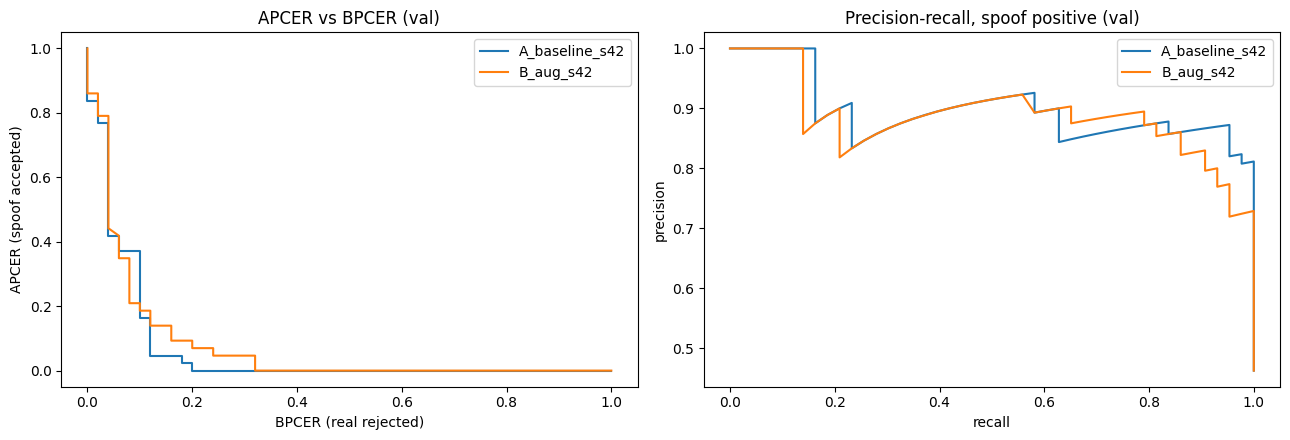

In [ ]:
# ===== NEW 6. TASK 2 — FULL VALIDATION REPORT for each run (loaded fresh from Drive) =====
import matplotlib.pyplot as plt
def bootstrap_ci(y, p, thr, n=2000, seed=SEED):
    rng = np.random.default_rng(seed); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keys = ["precision", "recall", "f1", "precision_real", "recall_real", "f1_real", "bacc"]; out = {k: [] for k in keys + ["auc", "ap"]}
    for _ in range(n):
        ib = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]); r = rates(y[ib], p[ib], thr)
        for k in keys: out[k].append(r[k])
        out["auc"].append(roc_auc_score(y[ib], p[ib])); out["ap"].append(average_precision_score(y[ib], p[ib]))
    return {k: (np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)) for k, v in out.items()}

def report(y, p, thr, title):
    r, ci = rates(y, p, thr), bootstrap_ci(y, p, thr)
    a, b = wilson(r["fn"], r["n_spoof"]), wilson(r["fp"], r["n_real"])
    print(f"\n==== {title} | threshold {thr:.3f} | n_real={r['n_real']}  n_spoof={r['n_spoof']} ====")
    print(f"ROC-AUC {roc_auc_score(y, p):.4f} [{ci['auc'][0]:.4f}, {ci['auc'][1]:.4f}] | "
          f"PR-AUC {average_precision_score(y, p):.4f} [{ci['ap'][0]:.4f}, {ci['ap'][1]:.4f}]")
    print(f"              pred REAL   pred SPOOF\n  true REAL    TN {r['tn']:4d}     FP {r['fp']:4d}\n"
          f"  true SPOOF   FN {r['fn']:4d}     TP {r['tp']:4d}")
    print(f"APCER (spoof accepted) {r['apcer']:6.2%}  95% [{a[0]:.2%}, {a[1]:.2%}]  ({r['fn']}/{r['n_spoof']})")
    print(f"BPCER (real rejected)  {r['bpcer']:6.2%}  95% [{b[0]:.2%}, {b[1]:.2%}]  ({r['fp']}/{r['n_real']})")
    print(f"Balanced accuracy      {r['bacc']:6.2%}  95% [{ci['bacc'][0]:.2%}, {ci['bacc'][1]:.2%}]")
    display(pd.DataFrame({
        "precision": [r["precision_real"], r["precision"]], "precision 95%": [ci["precision_real"], ci["precision"]],
        "recall": [r["recall_real"], r["recall"]], "recall 95%": [ci["recall_real"], ci["recall"]],
        "F1": [r["f1_real"], r["f1"]], "F1 95%": [ci["f1_real"], ci["f1"]], "support": [r["n_real"], r["n_spoof"]]},
        index=["Real (0)", "Spoof (1)"]).map(lambda v: f"[{v[0]:.3f}, {v[1]:.3f}]" if isinstance(v, tuple) else v).round(4))
    return {**r, "auc": roc_auc_score(y, p), "ap": average_precision_score(y, p)}

RESULTS, PROBS = [], {}
for s_ in TRAIN_SUMMARIES:
    path = RUN_DIR / s_["run"] / "best.pth"
    ck_ = torch.load(path, map_location=DEVICE, weights_only=False)
    m_ = FullFrameMoireNet().to(DEVICE); m_.load_state_dict(ck_["state_dict"], strict=True)
    p, y, _ = predict_logits(val_loader, m_); PROBS[s_["run"]] = p
    assert p[y == 1].mean() > p[y == 0].mean(), "class mapping looks inverted"
    print(f"\n######## {s_['run']} | epoch {ck_['epoch']} | stored val AUC {ck_['val_auc']:.4f} | re-computed {roc_auc_score(y, p):.4f}")
    r05 = report(y, p, 0.5, f"{s_['run']} @ 0.5")
    rth = report(y, p, ck_["threshold"], f"{s_['run']} @ val-selected threshold (APCER cap {APCER_CAP:.0%}, provisional)")
    sweep = pd.DataFrame([rates(y, p, t) for t in np.round(np.arange(0.10, 0.901, 0.05), 2)])
    display(sweep[["thr", "fp", "fn", "apcer", "bpcer", "precision", "recall", "precision_real", "recall_real", "bacc"]].round(3))
    RESULTS.append({"run": s_["run"], "epoch": ck_["epoch"], "auc": rth["auc"], "pr_auc": rth["ap"],
                    "FP@0.5": r05["fp"], "FN@0.5": r05["fn"], "bacc@0.5": r05["bacc"],
                    "thr": ck_["threshold"], "FP@thr": rth["fp"], "FN@thr": rth["fn"], "APCER@thr": rth["apcer"],
                    "BPCER@thr": rth["bpcer"], "spoof_P@thr": rth["precision"], "spoof_R@thr": rth["recall"],
                    "real_P@thr": rth["precision_real"], "real_R@thr": rth["recall_real"]})
    del m_

CMP = pd.DataFrame(RESULTS); display(CMP.round(4)); CMP.to_csv(RUN_DIR / "val_comparison.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for k, p in PROBS.items():
    fpr, tpr, _ = roc_curve(y, p); pp, rr, _ = precision_recall_curve(y, p)
    ax[0].plot(fpr, 1 - tpr, label=k); ax[1].plot(rr, pp, label=k)
ax[0].set(title="APCER vs BPCER (val)", xlabel="BPCER (real rejected)", ylabel="APCER (spoof accepted)"); ax[0].legend()
ax[1].set(title="Precision-recall, spoof positive (val)", xlabel="recall", ylabel="precision"); ax[1].legend()
plt.tight_layout(); plt.savefig(RUN_DIR / "val_comparison.png", dpi=110); plt.show()

Loaded best epoch 15 | val AUC 0.9508 | threshold 0.500
Copy of 6ac7aa42cf563e4bb707089e_checkin.jpg       -> SPOOF p(spoof)=0.986 | true SPOOF
Copy of 25_3.jpeg                                  -> SPOOF p(spoof)=0.993 | true SPOOF
6ac86d7f9453982821978ad8_checkin.jpg               -> REAL  p(spoof)=0.030 | true REAL
Copy of 85_2.jpeg                                  -> SPOOF p(spoof)=0.894 | true SPOOF
Copy of 82_2.jpeg                                  -> SPOOF p(spoof)=0.878 | true SPOOF
Copy of 6ac91bd00b3f3550e3318e7d_checkin.jpg       -> SPOOF p(spoof)=0.931 | true SPOOF
6ac5a3a42a92dc79eab5d940_checkin.jpg               -> REAL  p(spoof)=0.122 | true REAL
6ac7b82475c9a02de55de8ab_checkin.jpg               -> REAL  p(spoof)=0.063 | true REAL
Copy of 31_3.jpeg                                  -> SPOOF p(spoof)=0.881 | true SPOOF
6ac5a15e945398282196f413_checkin.jpg               -> REAL  p(spoof)=0.097 | true REAL
6ac70ffbc55d39617f3062c3_checkout.jpg              -> REAL  p(spoof)

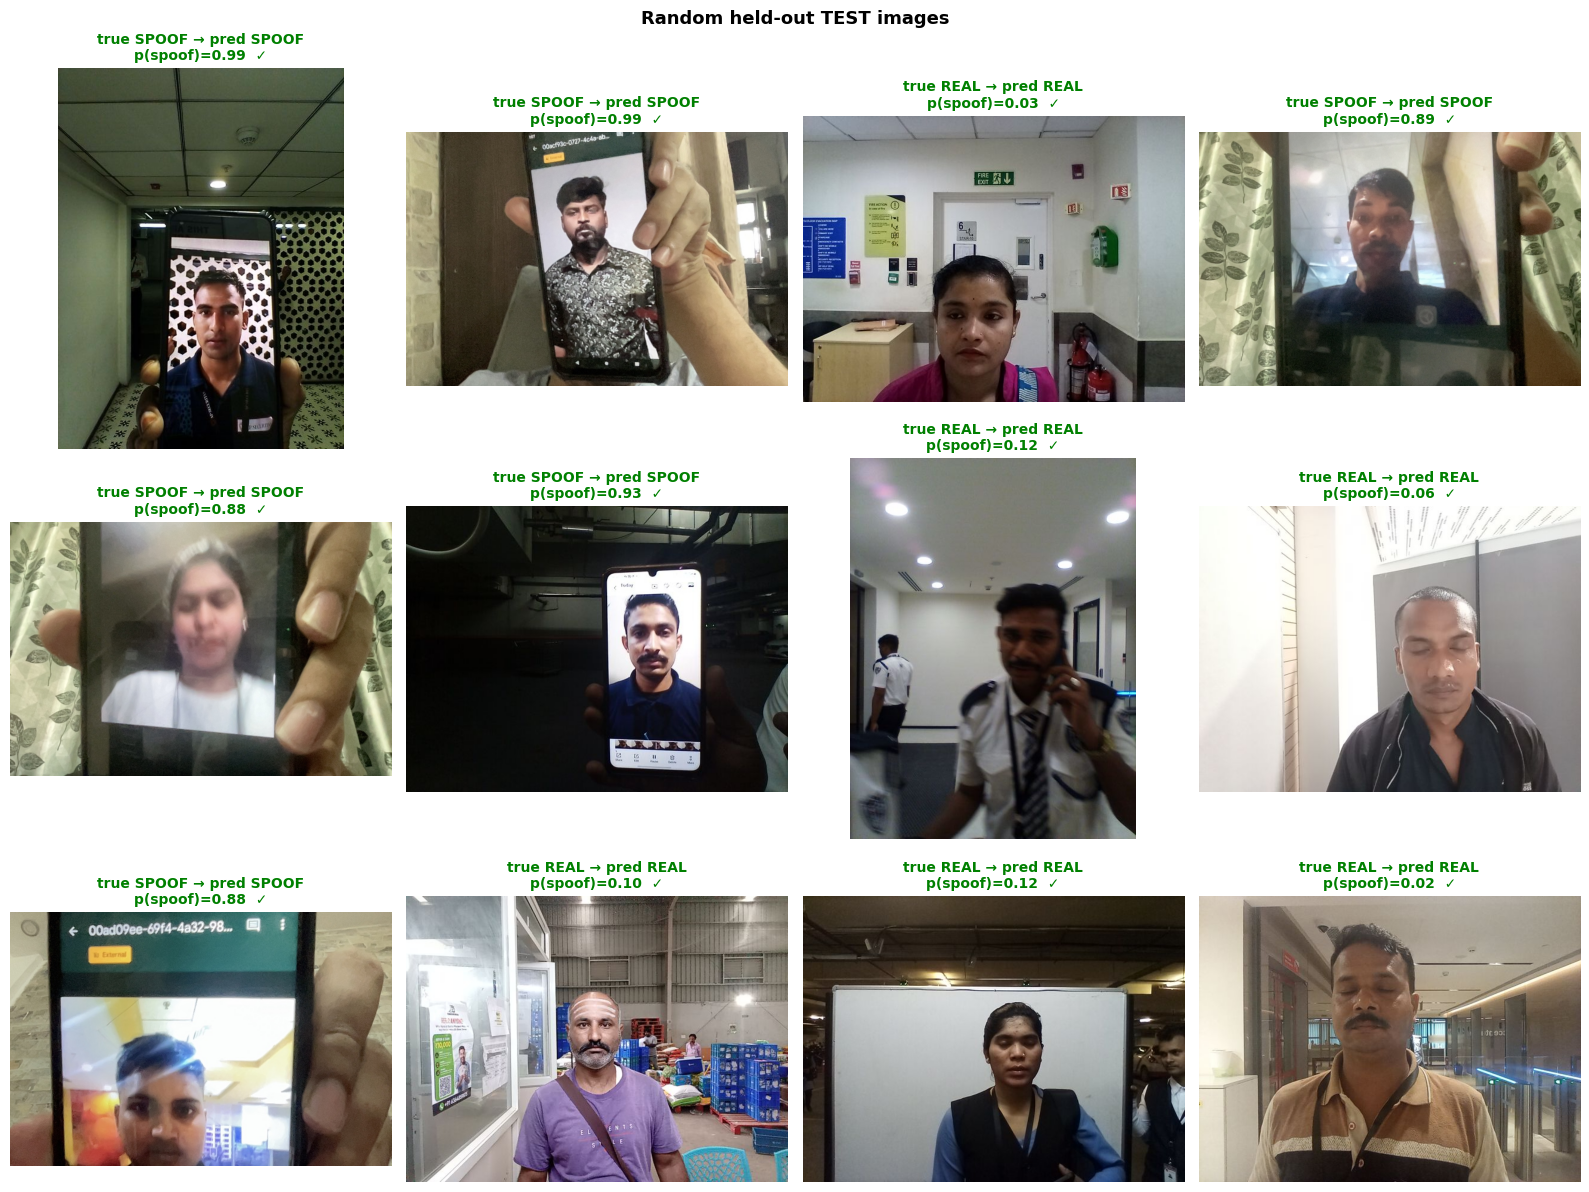


Correct: 12/12 (100%) at threshold 0.500


In [ ]:
# ===== INFERENCE: random test images / upload / Drive folder =====
import matplotlib.pyplot as plt

# ---- load best checkpoint (weights + threshold chosen on validation) ----
ck = torch.load(BEST, map_location=DEVICE, weights_only=False)
model.load_state_dict(ck["state_dict"]); model.eval()
THR = float(ck.get("threshold", 0.5))
print(f"Loaded best epoch {ck['epoch']} | val AUC {ck['val_auc']:.4f} | threshold {THR:.3f}")

@torch.no_grad()
def predict_image(path, thr=THR):
    """Same preprocessing as validation: letterboxed global frame + 3x3 native-resolution FFT patches."""
    img  = load_bgr(path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    spec = np.stack([spectrum(p) for p in native_patches(gray, train=False)])[:, None]     # (9,1,SPEC,SPEC)
    g    = letterbox(img, GLOBAL_SIZE).astype(np.float32) / 127.5 - 1.0
    g_t  = torch.from_numpy(g.transpose(2, 0, 1))[None].to(DEVICE)
    s_t  = torch.from_numpy(spec)[None].to(DEVICE)
    p = torch.softmax(model(g_t, s_t).float(), 1)[0, 1].item()
    return ("SPOOF" if p >= thr else "REAL"), p, img

def show_grid(paths, true_labels=None, cols=4, title=""):
    rows = (len(paths) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4.2), squeeze=False)
    for ax in axes.flat: ax.axis("off")
    n_ok = 0
    for i, (ax, path) in enumerate(zip(axes.flat, paths)):
        label, p, img = predict_image(path)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if true_labels is not None:
            truth = ["REAL", "SPOOF"][true_labels[i]]; ok = (truth == label); n_ok += ok
            ax.set_title(f"true {truth} → pred {label}\np(spoof)={p:.2f}  {'✓' if ok else '✗'}",
                         color="green" if ok else "red", fontsize=10, fontweight="bold")
        else:
            ax.set_title(f"{label}\np(spoof)={p:.2f}", color="red" if label == "SPOOF" else "green",
                         fontsize=11, fontweight="bold")
        print(f"{Path(path).name:50s} -> {label:5s} p(spoof)={p:.3f}"
              + (f" | true {['REAL','SPOOF'][true_labels[i]]}" if true_labels is not None else ""))
    fig.suptitle(title, fontsize=13, fontweight="bold"); plt.tight_layout(); plt.show()
    if true_labels is not None:
        print(f"\nCorrect: {n_ok}/{len(paths)} ({100 * n_ok / len(paths):.0f}%) at threshold {THR:.3f}")

# ===================== MODE A: random HELD-OUT test images =====================
N_EACH = 6                                   # images per class
rng = random.Random()                        # new random pick every run (use random.Random(0) to fix)
test_real  = [p for p, y in splits["test"] if y == 0]
test_spoof = [p for p, y in splits["test"] if y == 1]
pick = rng.sample(test_real, min(N_EACH, len(test_real))) + rng.sample(test_spoof, min(N_EACH, len(test_spoof)))
labs = [0] * min(N_EACH, len(test_real)) + [1] * min(N_EACH, len(test_spoof))
order = list(range(len(pick))); rng.shuffle(order)
show_grid([pick[i] for i in order], [labs[i] for i in order], title="Random held-out TEST images")

In [ ]:
# Zero out the moire spectra -> how much does test AUC drop? (large drop = moire branch carries signal)
@torch.no_grad()
def predict_ablate(loader, kill="moire"):
    model.eval(); P, Y = [], []
    for g, s, y in loader:
        g, s = g.to(DEVICE), s.to(DEVICE)
        if kill == "moire": s = torch.zeros_like(s)
        if kill == "rgb":   g = torch.zeros_like(g)
        P.append(torch.softmax(model(g, s).float(), 1)[:, 1].cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()
for k in ["none", "moire", "rgb"]:
    p, y = predict_ablate(test_loader, k) if k != "none" else (p_te, y_te)
    print(f"branch removed: {k:6s} -> test AUC {roc_auc_score(y, p):.4f}")

NameError: name 'torch' is not defined

In [ ]:
# ===== PREP FOR THE FINAL TEST EVAL (defines everything the old EVAL 2 + ablation cells expect) =====
from sklearn.metrics import brier_score_loss, precision_recall_curve
import matplotlib.pyplot as plt

TEST_TAG = "A_baseline_s42"          # <-- the run you chose from the Step 10 val comparison (A or B)

ck_t = torch.load(RUN_DIR / TEST_TAG / "best.pth", map_location=DEVICE, weights_only=False)
model = FullFrameMoireNet().to(DEVICE)
model.load_state_dict(ck_t["state_dict"], strict=True); model.eval()      # 'model' is also used by the ablation cell
print(f"Testing {TEST_TAG} | epoch {ck_t['epoch']} | val AUC {ck_t['val_auc']:.4f}")

# the old cells expect a 'specificity' key in rates(); add it once (= real recall)
if "specificity" not in rates(np.array([0, 1]), np.array([0.1, 0.9]), 0.5):
    _rates_base = rates
    def rates(y, p, thr):
        r = _rates_base(y, p, thr); r["specificity"] = r["recall_real"]; return r

# both thresholds are chosen on VALIDATION only, never on test
p_va, y_va, _ = predict_logits(val_loader, model)
THR_APCER = float(ck_t["threshold"])                                       # saved in best.pth (APCER-cap rule)
THR_BACC  = float(max(np.unique(p_va), key=lambda t: rates(y_va, p_va, t)["bacc"]))
print(f"THR_APCER={THR_APCER:.3f} (APCER cap {APCER_CAP:.0%}) | THR_BACC={THR_BACC:.3f}  <- both from validation")

# test predictions, computed once
p_te, y_te, _ = predict_logits(test_loader, model)
print(f"test set: {int((y_te == 0).sum())} real, {int((y_te == 1).sum())} spoof")

NameError: name 'torch' is not defined

In [ ]:
# ============================================================
# EVAL 2 — TEST report (untouched set) with stratified bootstrap 95% CIs
# ============================================================
def ece(y, p, bins=10):
    e, edges = 0.0, np.linspace(0, 1, bins + 1)
    for i in range(bins):
        m = (p >= edges[i]) & ((p < edges[i + 1]) if i < bins - 1 else (p <= edges[i + 1]))
        if m.any(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return e

def bootstrap(y, p, thr, n=1000, seed=SEED):
    rng = np.random.default_rng(seed); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    keys = ["precision", "recall", "specificity", "f1", "bacc", "apcer", "bpcer"]; out = {k: [] for k in keys + ["auc"]}
    for _ in range(n):
        ib = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        r = rates(y[ib], p[ib], thr)
        for k in keys: out[k].append(r[k])
        out["auc"].append(roc_auc_score(y[ib], p[ib]))
    return {k: (np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)) for k, v in out.items()}

TEST_AUC, TEST_AP = roc_auc_score(y_te, p_te), average_precision_score(y_te, p_te)
print(f"==== TEST: {int((y_te == 0).sum())} real, {int((y_te == 1).sum())} spoof ====")
print(f"ROC-AUC {TEST_AUC:.4f} | PR-AUC {TEST_AP:.4f} | Brier {brier_score_loss(y_te, p_te):.4f} | ECE {ece(y_te, p_te):.4f}")

test_results = {}
for name, t in [("0.50", 0.50), ("A_apcer", THR_APCER), ("B_bacc", THR_BACC)]:
    r, ci = rates(y_te, p_te, t), bootstrap(y_te, p_te, t)
    test_results[name] = {**r, "ci95": ci}
    print(f"\n--- threshold {name} = {t:.2f} ---")
    for k, lab in [("specificity", "Real accepted (specificity)"), ("recall", "Spoof caught (recall)"),
                   ("precision", "Spoof precision"), ("f1", "Spoof F1"), ("bacc", "Balanced accuracy"),
                   ("apcer", "APCER (spoof accepted)"), ("bpcer", "BPCER (real rejected)")]:
        print(f"  {lab:28s} {r[k]:7.2%}   [{ci[k][0]:.2%}, {ci[k][1]:.2%}]")
    print(f"  Confusion  [[TN {r['tn']:3d}  FP {r['fp']:3d}]\n              [FN {r['fn']:3d}  TP {r['tp']:3d}]]")
    print(classification_report(y_te, (p_te >= t).astype(int), target_names=["real", "spoof"], digits=4))

# ---- Plots ----
fig, ax = plt.subplots(1, 4, figsize=(21, 4.5))
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], "k--")
ax[0].set(title=f"ROC (test) AUC={TEST_AUC:.3f}", xlabel="BPCER (real rejected)", ylabel="Spoof caught")
pp, rr, _ = precision_recall_curve(y_te, p_te)
ax[1].plot(rr, pp); ax[1].set(title=f"PR (test) AP={TEST_AP:.3f}", xlabel="recall", ylabel="precision")
ax[2].hist(p_te[y_te == 0], bins=25, alpha=0.6, color="green", label="real")
ax[2].hist(p_te[y_te == 1], bins=25, alpha=0.6, color="red", label="spoof")
for t, c in [(0.5, "gray"), (THR_APCER, "k"), (THR_BACC, "blue")]:
    ax[2].axvline(t, ls="--", c=c)
ax[2].legend(); ax[2].set(title="P(spoof) on test  (gray 0.5, black A, blue B)")
cm = confusion_matrix(y_te, (p_te >= THR_APCER).astype(int), labels=[0, 1])
ax[3].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax[3].text(j, i, str(v), ha="center", va="center", fontsize=15)
ax[3].set_xticks([0, 1], ["pred real", "pred spoof"]); ax[3].set_yticks([0, 1], ["real", "spoof"])
ax[3].set_title(f"Confusion @ A ({THR_APCER:.2f})")
plt.tight_layout(); plt.savefig(RUN_DIR / "test_eval.png", dpi=110); plt.show()

NameError: name 'SEED' is not defined

In [ ]:
assert "REAL_DIR" in globals() and "DEVICE" in globals(), "Run the CONFIG cell (step 1) first - it defines imports and paths"
from pathlib import Path
import json, collections
PHASE1_RUN = Path("/content/drive/MyDrive/checkpoints_fullframe_moire/run_20261026_061459")
PHASE1_TAG = "A_baseline_s42"
RUN_DIR = PHASE1_RUN
PHASE1_BEST = PHASE1_RUN / PHASE1_TAG / "best.pth"
assert PHASE1_BEST.exists(), PHASE1_BEST
man = json.load(open(PHASE1_RUN / "splits_phase1.json"))
splits = {k: [(str((REAL_DIR if y == 0 else SPOOF_DIR) / n), int(y)) for n, y in man[k]] for k in ["train", "val", "test"]}
assert all(Path(p).exists() for v in splits.values() for p, _ in v), "some Phase 1 files are missing"
USE_STRICT_SPLIT = bool(man.get("strict", False))
for k, v in splits.items():
    c = collections.Counter(y for _, y in v); print(f"Phase 1 {k:5s}: real={c[0]:4d} spoof={c[1]:4d}")
print("Phase 1 checkpoint:", PHASE1_BEST)

Phase 1 train: real= 245 spoof= 226
Phase 1 val  : real=  50 spoof=  43
Phase 1 test : real=  55 spoof=  41
Phase 1 checkpoint: /content/drive/MyDrive/checkpoints_fullframe_moire/run_20261026_061459/A_baseline_s42/best.pth


In [ ]:
RUN_DIR = PHASE1_RUN
PHASE1_BEST = PHASE1_RUN / PHASE1_TAG / "best.pth"
assert PHASE1_BEST.exists(), PHASE1_BEST
man = json.load(open(PHASE1_RUN / "splits_phase1.json"))
splits = {k: [(str((REAL_DIR if y == 0 else SPOOF_DIR) / n), int(y)) for n, y in man[k]] for k in ["train", "val", "test"]}
assert all(Path(p).exists() for v in splits.values() for p, _ in v), "some Phase 1 files are missing"
USE_STRICT_SPLIT = bool(man.get("strict", False))
for k, v in splits.items():
    c = collections.Counter(y for _, y in v); print(f"Phase 1 {k:5s}: real={c[0]:4d} spoof={c[1]:4d}")
print("Phase 1 checkpoint:", PHASE1_BEST)

NameError: name 'PHASE1_RUN' is not defined

In [ ]:
# ===== P2-1. PHASE 2 (NEW) DATASET + LABEL METADATA =====
import hashlib, pandas as pd
def list_imgs(d): return sorted(p for p in d.iterdir() if p.suffix.lower() in EXTS)
P2_ROOT   = Path("/content/drive/MyDrive/spoof_dataset new")          # <-- NEW dataset (your screenshot)
P2_REAL, P2_SPOOF = P2_ROOT / "full" / "real", P2_ROOT / "full" / "spoof"
P2_LABELS = P2_ROOT / "20261022-d1c084_labels.csv"
P2_DIR = PHASE1_RUN / f"phase2_from_{PHASE1_TAG}"; P2_DIR.mkdir(exist_ok=True)
for d in [P2_REAL, P2_SPOOF, P2_LABELS]: assert d.exists(), f"not found: {d}"

meta = pd.read_csv(P2_LABELS)
meta["file"] = meta.log_id + "_" + meta.event.map({"login": "checkin", "logout": "checkout"}) + ".jpg"
files = {**{p.name: (str(p), 0) for p in list_imgs(P2_REAL)}, **{p.name: (str(p), 1) for p in list_imgs(P2_SPOOF)}}
print(f"NEW dataset folders: real={sum(v[1] == 0 for v in files.values())}  spoof={sum(v[1] == 1 for v in files.values())}")
print("csv labels:", meta.label.value_counts().to_dict(), "| 'unsure' rows are excluded (not in the folders)")

P2 = meta[meta.label.isin(["real", "spoof"]) & meta.file.isin(files)].copy()
P2["y"] = (P2.label == "spoof").astype(int)
P2["path"] = [files[f][0] for f in P2.file]
assert set(files) <= set(P2.file), f"{len(set(files) - set(P2.file))} images have no csv row"
assert all(files[f][1] == y for f, y in zip(P2.file, P2.y)), "folder label disagrees with csv label"
P2["missed_by_shadow"] = (P2.y == 1) & (P2.shadow_verdict == 0)
P2["flagged_by_prod"]  = (P2.y == 0) & (P2.prod_verdict == 1)
print(f"Phase 2 usable: real={int((P2.y == 0).sum())} spoof={int((P2.y == 1).sum())} | sites={P2.site.nunique()}")

# ---- remove Phase 2 images that duplicate Phase 1 images (byte-identical); hashes cached so this is slow only once ----
def md5(p):
    with open(p, "rb") as f: return hashlib.md5(f.read()).hexdigest()
CACHE = P2_DIR / "md5_cache.csv"
cache = dict(pd.read_csv(CACHE).values) if CACHE.exists() else {}
def md5c(p):
    if p not in cache: cache[p] = md5(p)
    return cache[p]
p1_md5 = {md5c(p) for v in splits.values() for p, _ in tqdm(v, desc="md5 phase1", leave=False)}
P2["md5"] = [md5c(p) for p in tqdm(P2.path, desc="md5 phase2")]
pd.DataFrame(list(cache.items()), columns=["path", "md5"]).to_csv(CACHE, index=False)
dup = P2.md5.isin(p1_md5) | P2.md5.duplicated()
print(f"removed {int(dup.sum())} Phase 2 images duplicating Phase 1 or each other")
P2 = P2[~dup].reset_index(drop=True)
print(f"P2 ready: real={int((P2.y == 0).sum())} spoof={int((P2.y == 1).sum())}  -> next: P2-1b (downsample to 1000 real)")

NEW dataset folders: real=2214  spoof=320
csv labels: {'real': 2214, 'spoof': 320, 'unsure': 34} | 'unsure' rows are excluded (not in the folders)
Phase 2 usable: real=2214 spoof=320 | sites=239


md5 phase1:   0%|          | 0/471 [00:00<?, ?it/s]

md5 phase1:   0%|          | 0/93 [00:00<?, ?it/s]

md5 phase1:   0%|          | 0/96 [00:00<?, ?it/s]

md5 phase2:   0%|          | 0/2534 [00:00<?, ?it/s]

removed 40 Phase 2 images duplicating Phase 1 or each other
P2 ready: real=2174 spoof=320  -> next: P2-1b (downsample to 1000 real)


In [ ]:
# ===== P2-1b. DOWNSAMPLE PHASE 2 REAL TO 300 (all 320 spoofs kept) =====
N_REAL_P2         = 1000
Q_SPOOF_SITES     = 120   # reals from the 32 sites that have spoofs (stops "this background = spoof")
Q_HARD_NEG        = 90    # reals the 'prod' scorer wrongly flagged (known hard negatives)
HARD_PER_SITE_MAX = 25    # 157 of 188 hard negatives are from ONE site (BDC_10) -> cap it

assert (P2.y == 0).sum() > N_REAL_P2, "P2 is already downsampled (or empty) -> re-run P2-1 first, then this cell ONCE"

def round_robin(df, n, seed):
    """Shuffle, then take 1st image of every site, then 2nd of every site, ... -> maximum site diversity."""
    d = df.sample(frac=1, random_state=seed)
    d = d.assign(_r=d.groupby("site").cumcount()).sort_values("_r", kind="stable")
    return d.head(n).drop(columns="_r")

real_df     = P2[P2.y == 0]
spoof_sites = set(P2[P2.y == 1].site)
pick_a = round_robin(real_df[real_df.site.isin(spoof_sites)], Q_SPOOF_SITES, SEED)
left   = real_df.drop(pick_a.index)
hard   = left[left.flagged_by_prod]
hard   = hard.sample(frac=1, random_state=SEED).groupby("site").head(HARD_PER_SITE_MAX)   # per-site cap
pick_b = round_robin(hard, min(Q_HARD_NEG, len(hard)), SEED)
left   = left.drop(pick_b.index)
pick_c = round_robin(left, N_REAL_P2 - len(pick_a) - len(pick_b), SEED)

real_keep_p2   = pd.concat([pick_a, pick_b, pick_c])
P2_REAL_UNUSED = real_df.drop(real_keep_p2.index)          # kept aside for an extra BPCER check later
P2 = pd.concat([real_keep_p2, P2[P2.y == 1]]).reset_index(drop=True)
assert (P2.y == 0).sum() == N_REAL_P2 and (P2.y == 1).sum() == 320 and not P2.file.duplicated().any()

print(f"Phase 2 after downsampling: real={int((P2.y == 0).sum())}  spoof={int((P2.y == 1).sum())}")
print(f"  real from spoof sites: {len(pick_a)} | prod-flagged hard negatives: {int(real_keep_p2.flagged_by_prod.sum())}"
      f" from {real_keep_p2[real_keep_p2.flagged_by_prod].site.nunique()} sites"
      f" | real sites covered: {real_keep_p2.site.nunique()} of {real_df.site.nunique()}")
print("  hard negatives per site:", real_keep_p2[real_keep_p2.flagged_by_prod].site.value_counts().to_dict())
print(f"  real images set aside: {len(P2_REAL_UNUSED)}")

Phase 2 after downsampling: real=1000  spoof=320
  real from spoof sites: 120 | prod-flagged hard negatives: 58 from 14 sites | real sites covered: 237 of 237
  hard negatives per site: {'BDC_10': 28, 'CODC2A': 12, 'DDC_4A': 6, 'BDC_6': 2, 'BDC_9': 1, 'MDC_5C': 1, 'HDC_5A': 1, 'MDC_7': 1, 'CDC_5': 1, 'MDC_2B': 1, 'BDC_4C': 1, 'CODC1A': 1, 'BDC_7': 1, 'CDC_6': 1}
  real images set aside: 1174


In [ ]:
# ===== P2-2. SPLIT PHASE 2 BY SITE (70/15/15) =====
def site_split(df, rs):
    y, g, ix = df.y.values, df.site.values, np.arange(len(df))
    rest, te = next(StratifiedGroupKFold(7, shuffle=True, random_state=rs).split(ix, y, g))
    tr, va = next(StratifiedGroupKFold(6, shuffle=True, random_state=rs).split(rest, y[rest], g[rest]))
    return rest[tr], rest[va], te
assert (P2.y == 0).sum() == N_REAL_P2 and (P2.y == 1).sum() == 320, \
    f"P2 has {(P2.y == 0).sum()} real / {(P2.y == 1).sum()} spoof -> run P2-1b right before this cell"
MIN_SPOOF = max(15, int(0.10 * P2.y.sum()))   # each of val/test needs at least ~10% of all spoofs
best_rs, best_dev = None, 1e9                 # choose the seed whose CLASS COUNTS are closest to 70/15/15 (no metrics used)
for rs in range(30):
    tr, va, te = site_split(P2, rs)
    n_sp = [int(P2.y.values[i].sum()) for i in (va, te)]
    if min(n_sp) < MIN_SPOOF: continue
    dev = sum(abs(P2.y.values[i].mean() - P2.y.mean()) for i in (va, te)) + sum(abs(len(i) / len(P2) - .15) for i in (va, te))
    if dev < best_dev: best_rs, best_dev = rs, dev
assert best_rs is not None, f"no site split gives >={MIN_SPOOF} spoofs in both val and test"
tr, va, te = site_split(P2, best_rs)
P2["split"] = ""; P2.loc[tr, "split"] = "train"; P2.loc[va, "split"] = "val"; P2.loc[te, "split"] = "test"
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert set(P2[P2.split == a].site).isdisjoint(P2[P2.split == b].site), "SITE LEAKAGE"
    assert set(P2[P2.split == a].log_id).isdisjoint(P2[P2.split == b].log_id), "LOG LEAKAGE"
p2_splits = {k: list(zip(P2[P2.split == k].path, P2[P2.split == k].y)) for k in ["train", "val", "test"]}
print(f"site split seed {best_rs}")
display(P2.groupby("split").agg(real=("y", lambda s: int((s == 0).sum())), spoof=("y", "sum"), sites=("site", "nunique"),
        spoof_missed_by_shadow=("missed_by_shadow", "sum"), real_flagged_by_prod=("flagged_by_prod", "sum")))
P2.drop(columns=["md5"]).to_csv(P2_DIR / "phase2_split.csv", index=False)
print("saved", P2_DIR / "phase2_split.csv")

site split seed 10


,real,spoof,sites,spoof_missed_by_shadow,real_flagged_by_prod
split,,,,,
test,173,50,36,1,1
train,672,197,168,19,56
val,155,73,35,3,1


saved /content/drive/MyDrive/checkpoints_fullframe_moire/run_20261026_061459/phase2_from_A_baseline_s42/phase2_split.csv


In [ ]:
# ===== P2-3. BEFORE FINE-TUNING: how does the Phase 1 model do on fresh Phase 2 sites? =====
def mk_loader(items): return DataLoader(FullFrameMoireDS(items, False), BATCH, shuffle=False, num_workers=2, pin_memory=True)
P1_VAL, P2_VAL = splits["val"], p2_splits["val"]
VAL_SETS = {"p1_val": P1_VAL, "p2_val": P2_VAL}
VAL_LOADERS = {k: mk_loader(v) for k, v in VAL_SETS.items()}

def load_full(path):
    ck_ = torch.load(path, map_location=DEVICE, weights_only=False)
    m_ = FullFrameMoireNet().to(DEVICE); m_.load_state_dict(ck_["state_dict"], strict=True); m_.eval()
    return m_, ck_

def slice_table(p, thr, title):
    v = P2[P2.split == "val"].reset_index(drop=True); v["p"] = p; v["pred"] = (v.p >= thr).astype(int)
    rows = [("all real", v.y == 0, "BPCER"), ("all spoof", v.y == 1, "APCER"),
            ("reals flagged by prod", v.flagged_by_prod, "BPCER"), ("spoofs missed by shadow", v.missed_by_shadow, "APCER")]
    out = []
    for name, m, kind in rows:
        n = int(m.sum()); k = int(((v.pred == 1) & m).sum()) if kind == "BPCER" else int(((v.pred == 0) & m).sum())
        lo, hi = wilson(k, n) if n else (np.nan, np.nan)
        out.append({"slice": name, "n": n, "errors": k, kind: k / n if n else np.nan, "95% CI": f"[{lo:.1%}, {hi:.1%}]"})
    print(f"--- {title} @ {thr:.3f}"); display(pd.DataFrame(out))

m1, ck1 = load_full(PHASE1_BEST)
THR_P1 = float(ck1.get("threshold", 0.5))
BEFORE = {}
for k, dl in VAL_LOADERS.items():
    p, y, _ = predict_logits(dl, m1); r = rates(y, p, THR_P1)
    BEFORE[k] = {"auc": roc_auc_score(y, p), "ap": average_precision_score(y, p), **r, "p": p}
    print(f"Phase 1 model on {k}: AUC {BEFORE[k]['auc']:.4f} PR-AUC {BEFORE[k]['ap']:.4f} | @thr {THR_P1:.3f}: "
          f"FP {r['fp']}/{r['n_real']} (BPCER {r['bpcer']:.1%})  FN {r['fn']}/{r['n_spoof']} (APCER {r['apcer']:.1%})")
slice_table(BEFORE["p2_val"]["p"], THR_P1, "Phase 1 model, Phase 2 val slices")
del m1

Phase 1 model on p1_val: AUC 0.9381 PR-AUC 0.8991 | @thr 0.420: FP 6/50 (BPCER 12.0%)  FN 2/43 (APCER 4.7%)
Phase 1 model on p2_val: AUC 0.9300 PR-AUC 0.8550 | @thr 0.420: FP 57/155 (BPCER 36.8%)  FN 3/73 (APCER 4.1%)
--- Phase 1 model, Phase 2 val slices @ 0.420


,slice,n,errors,BPCER,95% CI,APCER
0,all real,155,57,0.367742,"[29.6%, 44.6%]",NaN
1,all spoof,73,3,NaN,"[1.4%, 11.4%]",0.041096
2,reals flagged by prod,1,1,1.000000,"[20.7%, 100.0%]",NaN
3,spoofs missed by shadow,3,0,NaN,"[0.0%, 56.2%]",0.000000


In [ ]:
# ===== SETUP (one cell): replaces config + P2-0 + preprocessing + model + helpers. Run this FIRST in every new session =====
from google.colab import drive
drive.mount('/content/drive')
import os, re, json, random, collections, math, hashlib, time, shutil
import numpy as np, cv2, torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
import pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, matthews_corrcoef)

# ---------------- paths ----------------
DATA_ROOT   = Path("/content/drive/MyDrive/spoof_dataset/full")              # Phase 1 (OLD) data
REAL_DIR, SPOOF_DIR = DATA_ROOT / "real", DATA_ROOT / "spoof>>>"
PHASE1_CKPT = Path("/content/drive/MyDrive/checkpoints/best_model.pth")       # original face-model weights
PHASE1_RUN  = Path("/content/drive/MyDrive/checkpoints_fullframe_moire/run_20261026_061459")
PHASE1_TAG  = "A_baseline_s42"
PHASE1_BEST = PHASE1_RUN / PHASE1_TAG / "best.pth"
RUN_DIR     = PHASE1_RUN
for p in [REAL_DIR, SPOOF_DIR, PHASE1_CKPT, PHASE1_BEST, PHASE1_RUN / "splits_phase1.json"]:
    assert p.exists(), f"not found: {p}"

# ---------------- constants (same as training) ----------------
GLOBAL_SIZE, PATCH, SPEC, N_TRAIN_PATCH, GRID = 320, 256, 128, 4, 3
BATCH, SEED, APCER_TARGET = 16, 42, 0.05
APCER_CAP = APCER_TARGET                       # PROVISIONAL security target
EXTS = {".jpg", ".jpeg", ".png", ".webp"}
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "Runtime > Change runtime type > T4 GPU"

# ---------------- Phase 1 split (OLD data: used for OLD val + replay) ----------------
man = json.load(open(PHASE1_RUN / "splits_phase1.json"))
splits = {k: [(str((REAL_DIR if y == 0 else SPOOF_DIR) / n), int(y)) for n, y in man[k]] for k in ["train", "val", "test"]}
assert all(Path(p).exists() for v in splits.values() for p, _ in v), "some Phase 1 files are missing"
for k, v in splits.items():
    c = collections.Counter(y for _, y in v); print(f"Phase 1 {k:5s}: real={c[0]:4d} spoof={c[1]:4d}")

# ---------------- preprocessing (unchanged) ----------------
def load_bgr(path):
    with Image.open(path) as im:
        return cv2.cvtColor(np.asarray(ImageOps.exif_transpose(im).convert("RGB")), cv2.COLOR_RGB2BGR)

def letterbox(img, size):
    h, w = img.shape[:2]; s = size / max(h, w)
    r = cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    c = np.zeros((size, size, 3), np.uint8); y0, x0 = (size - r.shape[0]) // 2, (size - r.shape[1]) // 2
    c[y0:y0 + r.shape[0], x0:x0 + r.shape[1]] = r
    return c

def random_zoom(img, lo=0.6, hi=1.6):
    s = np.random.uniform(lo, hi); h, w = img.shape[:2]
    if s >= 1:
        ch, cw = int(h / s), int(w / s); y0, x0 = np.random.randint(0, h - ch + 1), np.random.randint(0, w - cw + 1)
        return img[y0:y0 + ch, x0:x0 + cw]
    ph, pw = int(h * (1 / s - 1) / 2), int(w * (1 / s - 1) / 2)
    return cv2.copyMakeBorder(img, ph, ph, pw, pw, cv2.BORDER_REFLECT)

_HANN = {}
def spectrum(gray_patch):
    P = gray_patch.shape[0]
    if P not in _HANN: _HANN[P] = np.outer(np.hanning(P), np.hanning(P)).astype(np.float32)
    g = gray_patch.astype(np.float32); g -= g.mean()
    S = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g * _HANN[P]))))
    if P != SPEC: S = cv2.resize(S, (SPEC, SPEC), interpolation=cv2.INTER_AREA)
    return ((S - S.mean()) / (S.std() + 1e-6)).astype(np.float32)

def native_patches(gray, train):
    h, w = gray.shape; P = min(PATCH, h, w)
    if train:
        ys = np.clip(np.random.normal((h - P) / 2, (h - P) / 4 + 1, N_TRAIN_PATCH), 0, h - P).astype(int)
        xs = np.clip(np.random.normal((w - P) / 2, (w - P) / 4 + 1, N_TRAIN_PATCH), 0, w - P).astype(int)
        pos = list(zip(ys, xs))
    else:
        pos = [(y, x) for y in np.linspace(0, h - P, GRID).astype(int) for x in np.linspace(0, w - P, GRID).astype(int)]
    return [gray[y:y + P, x:x + P] for y, x in pos]

class FullFrameMoireDS(Dataset):
    def __init__(self, items, train): self.items, self.train = items, train
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        path, y = self.items[i]; img = load_bgr(path)
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        if self.train and np.random.rand() < 0.5: gray = cv2.flip(gray, 1)
        spec = np.stack([spectrum(p) for p in native_patches(gray, self.train)])[:, None]
        g = img
        if self.train:
            g = random_zoom(g)
            if np.random.rand() < 0.5: g = cv2.flip(g, 1)
            if np.random.rand() < 0.5:
                g = cv2.convertScaleAbs(g, alpha=np.random.uniform(0.85, 1.15), beta=np.random.uniform(-12, 12))
        g = letterbox(g, GLOBAL_SIZE).astype(np.float32) / 127.5 - 1.0
        return torch.from_numpy(g.transpose(2, 0, 1)), torch.from_numpy(spec), y

# ---------------- model (unchanged architecture) ----------------
class MiniFASNetV2_Fixed(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.conv1 = self._ds(3, 8, 3, 1, 1);    self.conv2 = self._ds(8, 16, 3, 2, 1)
        self.conv3 = self._ds(16, 32, 3, 1, 1);  self.conv4 = self._ds(32, 64, 3, 2, 1)
        self.conv5 = self._ds(64, 128, 3, 1, 1); self.conv6 = self._ds(128, 256, 3, 2, 1)
        self.conv7 = self._ds(256, 256, 3, 1, 1)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1 = nn.Linear(256, 128); self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5); self.fc2 = nn.Linear(128, num_classes)
    def _ds(self, i, o, k, s, p):
        return nn.Sequential(nn.Conv2d(i, i, k, s, p, groups=i, bias=False), nn.BatchNorm2d(i), nn.ReLU(inplace=True),
                             nn.Conv2d(i, o, 1, 1, 0, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

def cbr(i, o, s): return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class FullFrameMoireNet(nn.Module):
    BLOCKS = ["conv1", "conv2", "conv3", "conv4", "conv5", "conv6", "conv7"]
    def __init__(self):
        super().__init__()
        self.rgb = MiniFASNetV2_Fixed()
        self.moire = nn.Sequential(cbr(1, 16, 2), cbr(16, 32, 2), cbr(32, 64, 2), cbr(64, 128, 2), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Linear(256 + 128, 128), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, 2))
    def rgb_feats(self, x):
        for b in self.BLOCKS: x = getattr(self.rgb, b)(x)
        return self.rgb.avgpool(x).flatten(1)
    def forward(self, glob, spec):
        B, N = spec.shape[:2]
        m = self.moire(spec.flatten(0, 1)).flatten(1).view(B, N, -1).mean(1)
        return self.head(torch.cat([self.rgb_feats(glob), m], 1))

# ---------------- metric / threshold helpers ----------------
def _div(a, b): return a / b if b else float("nan")
def rates(y, p, thr):
    y = np.asarray(y).astype(int); pred = (np.asarray(p) >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    rs, rr, ps, pr = _div(tp, tp + fn), _div(tn, tn + fp), _div(tp, tp + fp), _div(tn, tn + fn)
    return dict(thr=float(thr), n_real=int(tn + fp), n_spoof=int(tp + fn), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp),
                precision=ps, recall=rs, f1=_div(2 * ps * rs, ps + rs),
                precision_real=pr, recall_real=rr, f1_real=_div(2 * pr * rr, pr + rr),
                bacc=(rs + rr) / 2, apcer=_div(fn, fn + tp), bpcer=_div(fp, fp + tn))

def wilson(k, n, z=1.96):
    if n == 0: return (float("nan"), float("nan"))
    ph = k / n; d = 1 + z * z / n; c = ph + z * z / (2 * n); r = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n))
    return (max(0.0, (c - r) / d), min(1.0, (c + r) / d))

def thr_for_apcer(y, p, cap):
    y, p = np.asarray(y), np.asarray(p); s = np.sort(p[y == 1]); k = int(math.floor(cap * len(s) + 1e-9))
    if k >= len(s): return 1.0
    below = p[p < s[k]]
    return float((s[k] + below.max()) / 2) if len(below) else float(s[k])

@torch.no_grad()
def predict_logits(loader, mdl):
    mdl.eval(); L, Y = [], []
    for g, s, y in loader:
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            L.append(mdl(g.to(DEVICE), s.to(DEVICE)).float().cpu())
        Y.append(y)
    L = torch.cat(L); return torch.softmax(L, 1)[:, 1].numpy(), torch.cat(Y).numpy(), L

def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()

# ---------------- self-check: the Phase 1 checkpoint loads and reproduces its validation AUC ----------------
_m = FullFrameMoireNet().to(DEVICE); _ck = torch.load(PHASE1_BEST, map_location=DEVICE, weights_only=False)
_m.load_state_dict(_ck["state_dict"], strict=True)
_p, _y, _ = predict_logits(DataLoader(FullFrameMoireDS(splits["val"], False), BATCH, num_workers=2), _m)
print(f"✓ SETUP OK | {PHASE1_TAG}/best.pth epoch {_ck['epoch']} | P1 val AUC {roc_auc_score(_y, _p):.4f} (stored {_ck['val_auc']:.4f})"
      f" | threshold {_ck.get('threshold', float('nan')):.3f}")
del _m, _ck

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Phase 1 train: real= 245 spoof= 226
Phase 1 val  : real=  50 spoof=  43
Phase 1 test : real=  55 spoof=  41
✓ SETUP OK | A_baseline_s42/best.pth epoch 18 | P1 val AUC 0.9381 (stored 0.9381) | threshold 0.420


loaded A_baseline_s42/best.pth | start: OLD val AUC 0.9381 | NEW val AUC 0.9300 loss 0.441
train: new 869 + Phase-1 replay 235 = 1104 (real 787, spoof 317) | hard negatives x1.5: 56
trainable params: 262,162 | BN frozen in: ['conv1', 'conv2', 'conv3', 'conv4', 'conv5']
monitoring threshold (fixed, for trend only): 0.420
selection: lowest NEW val loss with OLD val AUC >= 0.9281


FT ep 1:   0%|          | 0/69 [00:00<?, ?it/s]


FT ep  1/40 | lr 1.5e-04 | 27s | train loss 0.448 acc  81.6% | val-train loss gap -0.035
   NEW val | loss 0.412 | acc  77.6% | real ok  69.0% (107/155) | spoof caught  95.9% (70/73) | spoof prec  59.3% | F1 0.733 | bal-acc  82.5% | MCC +0.606 | AUC 0.9320
   OLD val | loss 0.335 | acc  89.2% | real ok  86.0% (43/50) | spoof caught  93.0% (40/43) | spoof prec  85.1% | F1 0.889 | bal-acc  89.5% | MCC +0.788 | AUC 0.9400
   NEW val genuine rejected when spoof acceptance is capped at 5%: 27.1%
   ✓ best saved (EMA) NEW loss 0.412 AUC 0.9320 / OLD AUC 0.9400


FT ep 2:   0%|          | 0/69 [00:00<?, ?it/s]


FT ep  2/40 | lr 3.0e-04 | 27s | train loss 0.437 acc  81.8% | val-train loss gap +0.095
   NEW val | loss 0.532 | acc  63.6% | real ok  47.1% (73/155) | spoof caught  98.6% (72/73) | spoof prec  46.8% | F1 0.634 | bal-acc  72.9% | MCC +0.456 | AUC 0.9305
   OLD val | loss 0.361 | acc  87.1% | real ok  78.0% (39/50) | spoof caught  97.7% (42/43) | spoof prec  79.2% | F1 0.875 | bal-acc  87.8% | MCC +0.762 | AUC 0.9400
   NEW val genuine rejected when spoof acceptance is capped at 5%: 29.7%
   no improvement (1/12)


FT ep 3:   0%|          | 0/69 [00:00<?, ?it/s]

... (53 outputs left out)

FT ep 30:   0%|          | 0/69 [00:00<?, ?it/s]


FT ep 30/40 | lr 5.8e-05 | 27s | train loss 0.274 acc  90.9% | val-train loss gap +0.067
   NEW val | loss 0.342 | acc  85.1% | real ok  83.2% (129/155) | spoof caught  89.0% (65/73) | spoof prec  71.4% | F1 0.793 | bal-acc  86.1% | MCC +0.688 | AUC 0.9306
   OLD val | loss 0.232 | acc  95.7% | real ok  92.0% (46/50) | spoof caught 100.0% (43/43) | spoof prec  91.5% | F1 0.956 | bal-acc  96.0% | MCC +0.917 | AUC 0.9665
   NEW val genuine rejected when spoof acceptance is capped at 5%: 29.0%
   no improvement (11/12)


FT ep 31:   0%|          | 0/69 [00:00<?, ?it/s]


FT ep 31/40 | lr 4.8e-05 | 27s | train loss 0.275 acc  91.5% | val-train loss gap +0.056
   NEW val | loss 0.331 | acc  85.1% | real ok  83.9% (130/155) | spoof caught  87.7% (64/73) | spoof prec  71.9% | F1 0.790 | bal-acc  85.8% | MCC +0.684 | AUC 0.9312
   OLD val | loss 0.224 | acc  95.7% | real ok  92.0% (46/50) | spoof caught 100.0% (43/43) | spoof prec  91.5% | F1 0.956 | bal-acc  96.0% | MCC +0.917 | AUC 0.9670
   NEW val genuine rejected when spoof acceptance is capped at 5%: 29.7%
   no improvement (12/12)
Early stop


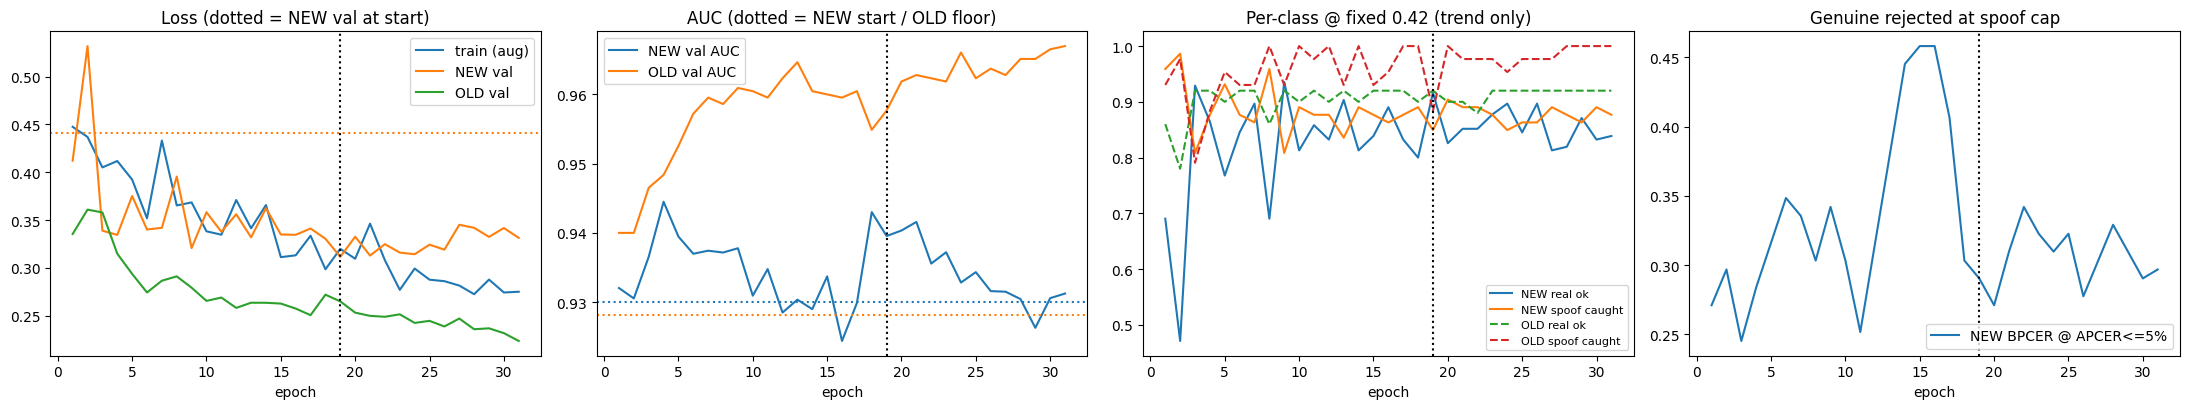


clean NEW-train: loss 0.199 AUC 0.9705  vs  NEW val: loss 0.312 AUC 0.9395
→ fits train well, val lags: GENERALISATION limit (new sites) -> more / more varied spoof data needed
Mounted at /content/drive
✓ 4 files verified in Drive -> /content/drive/MyDrive/checkpoints_fullframe_moire/run_20261026_061459/phase2_from_A_baseline_s42/ft_v3_from_A_s42_replay0.5_real1000
{
  "tag": "ft_v3_from_A_s42_replay0.5_real1000",
  "best_epoch": 19,
  "p2_val_auc": 0.9395492708793637,
  "p2_val_auc_before": 0.9300044189129474,
  "p2_gain": 0.009544851966416301,
  "p2_val_loss": 0.3115192949771881,
  "p2_val_loss_before": 0.4411754608154297,
  "p1_val_auc": 0.9576744186046512,
  "p1_val_auc_before": 0.9381395348837209,
  "p1_change": 0.019534883720930263,
  "new_val_bpcer@cap": 0.2903225806451613,
  "threshold": 0.2283286154270172,
  "train_clean_auc": 0.9705478003384094,
  "train_clean_loss": 0.19936029613018036,
  "epochs_run": 31,
  "minutes": 14.5
}
⚠ NEW val AUC gained < 0.01 over the Phase 1 mod

In [ ]:
# ===== P2-4 v3. FINE-TUNE A_baseline_s42 ON THE NEW DATASET — underfitting fixes =====
# v3 vs v2: Phase 1 LRs restored (head 3e-4, conv6-7 1e-4) | BN frozen only in conv1-5 (conv6-7 + moire adapt)
#           EMA 0.98 (less lag) | hard negatives x1.5 | patience 12
#           selection = lowest NEW val loss while OLD val AUC stays within P1_TOL of its start
#           + clean (non-augmented) train check at the end to tell underfitting from poor generalisation
import shutil, time, hashlib, copy, math
import torch.nn.functional as F
from google.colab import drive
from sklearn.metrics import matthews_corrcoef

# ---------------- settings ----------------
INIT_CKPT  = PHASE1_RUN / "A_baseline_s42" / "best.pth"
FT_SEED    = 42
FT_EPOCHS, FT_PATIENCE, WARMUP = 40, 12, 2
FT_FROZEN  = ["conv1", "conv2", "conv3"]                    # weights frozen
BN_FROZEN  = ["conv1", "conv2", "conv3", "conv4", "conv5"]  # BN running stats frozen (pretrained blocks only)
LR = {"conv45": 1e-5, "conv67": 1e-4, "new": 3e-4}           # = Phase 1 rates (v2 head LR was 3x too low)
REPLAY_P1  = 0.5          # 50% of Phase 1 train mixed in -> no forgetting (v2: old AUC went UP, keep it)
HARD_W     = 1.5          # sampling weight for prod-flagged reals (v2: 2.0)
EMA_DECAY  = 0.98         # ~50-step average (v2: 0.99 lagged behind)
P1_TOL     = 0.01         # max allowed drop in OLD val AUC for a checkpoint to be selectable
FT_TAG     = f"ft_v3_from_A_s{FT_SEED}_replay{REPLAY_P1}_real{N_REAL_P2}"

# ---------------- 1. load the best Phase 1 model and prove it is the right one ----------------
ck0 = torch.load(INIT_CKPT, map_location=DEVICE, weights_only=False)
model = FullFrameMoireNet().to(DEVICE)
model.load_state_dict(ck0["state_dict"], strict=True)
p0, y0, L0 = predict_logits(VAL_LOADERS["p1_val"], model)
P1_BASE = roc_auc_score(y0, p0)
assert abs(P1_BASE - ck0["val_auc"]) < 0.01, "loaded weights do not reproduce the stored AUC"
p0n, y0n, L0n = predict_logits(VAL_LOADERS["p2_val"], model)
P2_BASE, P2_BASE_LOSS = roc_auc_score(y0n, p0n), F.cross_entropy(L0n, torch.as_tensor(y0n)).item()
print(f"loaded {INIT_CKPT.parent.name}/best.pth | start: OLD val AUC {P1_BASE:.4f} | "
      f"NEW val AUC {P2_BASE:.4f} loss {P2_BASE_LOSS:.3f}")

# ---------------- 2. data: new train + Phase 1 replay, hard negatives oversampled ----------------
random.seed(FT_SEED); np.random.seed(FT_SEED); torch.manual_seed(FT_SEED)
replay   = random.Random(FT_SEED).sample(splits["train"], int(len(splits["train"]) * REPLAY_P1))
ft_train = p2_splits["train"] + replay
hard_set = set(P2[(P2.split == "train") & P2.flagged_by_prod].path)
cnt = collections.Counter(y for _, y in ft_train)
w   = [(1.0 / cnt[y]) * (HARD_W if p in hard_set else 1.0) for p, y in ft_train]
smp = WeightedRandomSampler(w, len(ft_train), replacement=True, generator=torch.Generator().manual_seed(FT_SEED))
ft_loader = DataLoader(FullFrameMoireDS(ft_train, True), BATCH, sampler=smp, num_workers=2, pin_memory=True,
                       drop_last=True, persistent_workers=True)
print(f"train: new {len(p2_splits['train'])} + Phase-1 replay {len(replay)} = {len(ft_train)} "
      f"(real {cnt[0]}, spoof {cnt[1]}) | hard negatives x{HARD_W}: {len(hard_set)}")

# ---------------- 3. what trains ----------------
for p in model.parameters(): p.requires_grad = True
for b in FT_FROZEN:
    for p in getattr(model.rgb, b).parameters(): p.requires_grad = False
for p in list(model.rgb.fc1.parameters()) + list(model.rgb.fc2.parameters()): p.requires_grad = False
def bn_freeze():
    """Call AFTER every model.train(): BN stats frozen in pretrained conv1-5; conv6-7 + moire BN adapt."""
    for b in BN_FROZEN:
        for mod in getattr(model.rgb, b).modules():
            if isinstance(mod, nn.BatchNorm2d): mod.eval()

groups = [{"params": [p for b in ["conv4", "conv5"] for p in getattr(model.rgb, b).parameters()], "lr": LR["conv45"]},
          {"params": [p for b in ["conv6", "conv7"] for p in getattr(model.rgb, b).parameters()], "lr": LR["conv67"]},
          {"params": list(model.moire.parameters()) + list(model.head.parameters()), "lr": LR["new"]}]
optimizer = optim.AdamW(groups, weight_decay=1e-4)
def lr_factor(e):                                        # linear warmup, then cosine down to 2%
    if e < WARMUP: return (e + 1) / WARMUP
    return max(0.02, 0.5 * (1 + math.cos(math.pi * (e - WARMUP) / (FT_EPOCHS - WARMUP))))
scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

ema = copy.deepcopy(model).eval()
for p in ema.parameters(): p.requires_grad_(False)
@torch.no_grad()
def ema_update():
    for e, m in zip(ema.state_dict().values(), model.state_dict().values()):
        if e.dtype.is_floating_point: e.mul_(EMA_DECAY).add_(m.detach(), alpha=1 - EMA_DECAY)
        else: e.copy_(m)                                  # BN step counters

n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable params: {n_train:,} | BN frozen in: {BN_FROZEN}")

# ---------------- 4. output folders (local first, then verified copy to Drive) ----------------
local, remote = Path("/content/ckpt_local") / FT_TAG, P2_DIR / FT_TAG
local.mkdir(parents=True, exist_ok=True); remote.mkdir(parents=True, exist_ok=True)
def push(f):
    shutil.copy2(f, remote / f.name); assert (remote / f.name).stat().st_size == f.stat().st_size, f"copy failed: {f.name}"
def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()

# ---------------- 5. training loop (metrics computed on the EMA model) ----------------
MON_THR = float(ck0.get("threshold", 0.5))

def epoch_metrics(y, p, L, thr):
    pred = (p >= thr).astype(int); r = rates(y, p, thr)
    return {"loss": F.cross_entropy(L, torch.as_tensor(y)).item(), "acc": (pred == y).mean(),
            "real_ok": r["recall_real"], "spoof_caught": r["recall"], "spoof_prec": r["precision"],
            "real_prec": r["precision_real"], "f1": r["f1"], "bacc": r["bacc"], "mcc": matthews_corrcoef(y, pred),
            "fp": r["fp"], "fn": r["fn"], "n_real": r["n_real"], "n_spoof": r["n_spoof"], "auc": roc_auc_score(y, p)}

def fmt(name, m):
    return (f"   {name:8s}| loss {m['loss']:.3f} | acc {m['acc']:6.1%} | real ok {m['real_ok']:6.1%} "
            f"({m['n_real'] - m['fp']}/{m['n_real']}) | spoof caught {m['spoof_caught']:6.1%} ({m['n_spoof'] - m['fn']}/{m['n_spoof']})"
            f" | spoof prec {m['spoof_prec']:6.1%} | F1 {m['f1']:.3f} | bal-acc {m['bacc']:6.1%} | MCC {m['mcc']:+.3f} | AUC {m['auc']:.4f}")

print(f"monitoring threshold (fixed, for trend only): {MON_THR:.3f}")
print(f"selection: lowest NEW val loss with OLD val AUC >= {P1_BASE - P1_TOL:.4f}")
best, best_ep, bad, hist, t0 = -1e9, None, 0, [], time.time()
for ep in range(1, FT_EPOCHS + 1):
    te = time.time(); model.train(); bn_freeze(); tot = n = correct = 0
    for g, s, y in tqdm(ft_loader, desc=f"FT ep {ep}", leave=False):
        g, s, y = g.to(DEVICE, non_blocking=True), s.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE.type == "cuda"):
            out = model(g, s); loss = criterion(out, y)
        optimizer.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 2.0)
        scaler.step(optimizer); scaler.update(); ema_update()
        tot += loss.item() * y.size(0); n += y.size(0)
        correct += ((torch.softmax(out.float(), 1)[:, 1] >= MON_THR).long() == y).sum().item()
    lr_now = optimizer.param_groups[-1]["lr"]; scheduler.step()

    M, VP = {}, {}
    for k, dl in VAL_LOADERS.items():
        pv, yv, Lv = predict_logits(dl, ema); VP[k] = (pv, yv)
        M[k] = epoch_metrics(yv, pv, Lv, MON_THR)
    p2p, p2y = VP["p2_val"]
    bpcer_cap = rates(p2y, p2p, thr_for_apcer(p2y, p2p, APCER_CAP))["bpcer"]
    row = {"epoch": ep, "lr_head": lr_now, "sec": time.time() - te, "train_loss": tot / n, "train_acc": correct / n,
           "p2_bpcer@cap": bpcer_cap, **{f"{k}_{m}": v for k, d in M.items() for m, v in d.items()}}
    hist.append(row)
    print(f"\nFT ep {ep:2d}/{FT_EPOCHS} | lr {lr_now:.1e} | {row['sec']:.0f}s | train loss {row['train_loss']:.3f} "
          f"acc {row['train_acc']:6.1%} | val-train loss gap {row['p2_val_loss'] - row['train_loss']:+.3f}"
          + ("  <- overfitting?" if row['p2_val_loss'] - row['train_loss'] > 0.15 else ""))
    print(fmt("NEW val", M["p2_val"])); print(fmt("OLD val", M["p1_val"]))
    print(f"   NEW val genuine rejected when spoof acceptance is capped at {APCER_CAP:.0%}: {bpcer_cap:.1%}")

    old_ok = row["p1_val_auc"] >= P1_BASE - P1_TOL
    score  = -row["p2_val_loss"] if old_ok else -row["p2_val_loss"] - 1.0      # forgetting checkpoints can't win
    pd.DataFrame(hist).to_csv(local / "history.csv", index=False)
    if score > best + 2e-3:
        best, best_ep, bad = score, ep, 0
        torch.save({"state_dict": ema.state_dict(), "epoch": ep, "ema": EMA_DECAY,
                    "p1_val_auc": row["p1_val_auc"], "p2_val_auc": row["p2_val_auc"], "p2_val_loss": row["p2_val_loss"],
                    "init_from": str(INIT_CKPT),
                    "settings": {"lr": LR, "frozen": FT_FROZEN, "bn_frozen": BN_FROZEN, "replay_p1": REPLAY_P1,
                                 "hard_w": HARD_W, "ema": EMA_DECAY, "n_real_p2": N_REAL_P2, "seed": FT_SEED}},
                   local / "best.pth")
        push(local / "best.pth"); push(local / "history.csv")
        print(f"   ✓ best saved (EMA) NEW loss {row['p2_val_loss']:.3f} AUC {row['p2_val_auc']:.4f} / OLD AUC {row['p1_val_auc']:.4f}")
    else:
        bad += 1; print(f"   no improvement ({bad}/{FT_PATIENCE})" + ("" if old_ok else "  [old AUC dropped too far]"))
        if bad >= FT_PATIENCE: print("Early stop"); break

# ---------------- 5b. learning curves ----------------
import matplotlib.pyplot as plt
H = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 4, figsize=(22, 4.2))
ax[0].plot(H.epoch, H.train_loss, label="train (aug)"); ax[0].plot(H.epoch, H.p2_val_loss, label="NEW val"); ax[0].plot(H.epoch, H.p1_val_loss, label="OLD val")
ax[0].axhline(P2_BASE_LOSS, ls=":", c="C1"); ax[0].set(title="Loss (dotted = NEW val at start)", xlabel="epoch"); ax[0].legend()
ax[1].plot(H.epoch, H.p2_val_auc, label="NEW val AUC"); ax[1].plot(H.epoch, H.p1_val_auc, label="OLD val AUC")
ax[1].axhline(P2_BASE, ls=":", c="C0"); ax[1].axhline(P1_BASE - P1_TOL, ls=":", c="C1")
ax[1].set(title="AUC (dotted = NEW start / OLD floor)", xlabel="epoch"); ax[1].legend()
ax[2].plot(H.epoch, H.p2_val_real_ok, label="NEW real ok"); ax[2].plot(H.epoch, H.p2_val_spoof_caught, label="NEW spoof caught")
ax[2].plot(H.epoch, H.p1_val_real_ok, "--", label="OLD real ok"); ax[2].plot(H.epoch, H.p1_val_spoof_caught, "--", label="OLD spoof caught")
ax[2].set(title=f"Per-class @ fixed {MON_THR:.2f} (trend only)", xlabel="epoch"); ax[2].legend(fontsize=8)
ax[3].plot(H.epoch, H["p2_bpcer@cap"], label=f"NEW BPCER @ APCER<={APCER_CAP:.0%}")
ax[3].set(title="Genuine rejected at spoof cap", xlabel="epoch"); ax[3].legend()
for a in ax: a.axvline(best_ep, ls=":", c="k")
plt.tight_layout(); plt.savefig(local / "learning_curves.png", dpi=110); plt.show()

# ---------------- 6. threshold (chosen on old + new VALIDATION), final save, verified sync ----------------
ckb = torch.load(local / "best.pth", map_location=DEVICE, weights_only=False); model.load_state_dict(ckb["state_dict"])
model.eval()
P, Y = zip(*[predict_logits(VAL_LOADERS[k], model)[:2] for k in VAL_LOADERS])
ckb.update(threshold=thr_for_apcer(np.concatenate(Y), np.concatenate(P), APCER_CAP),
           threshold_rule=f"combined P1+P2 val, APCER <= {APCER_CAP} (PROVISIONAL)", class_map={0: "real", 1: "spoof"},
           score="softmax(logits)[:,1] = P(spoof)", decision="SPOOF if score >= threshold")
torch.save(ckb, local / "best.pth")

# ---------------- 7. underfitting check on CLEAN (non-augmented) NEW train images ----------------
clean_tr = DataLoader(FullFrameMoireDS(p2_splits["train"], False), BATCH, shuffle=False, num_workers=2)
pt, yt, Lt = predict_logits(clean_tr, model)
TRAIN_CLEAN_LOSS, TRAIN_CLEAN_AUC = F.cross_entropy(Lt, torch.as_tensor(yt)).item(), roc_auc_score(yt, pt)
print(f"\nclean NEW-train: loss {TRAIN_CLEAN_LOSS:.3f} AUC {TRAIN_CLEAN_AUC:.4f}  vs  NEW val: "
      f"loss {ckb['p2_val_loss']:.3f} AUC {ckb['p2_val_auc']:.4f}")
if TRAIN_CLEAN_AUC - ckb["p2_val_auc"] > 0.03:
    print("→ fits train well, val lags: GENERALISATION limit (new sites) -> more / more varied spoof data needed")
else:
    print("→ train ≈ val: still UNDERFITTING -> model capacity / LR is the limit")

bm = H[H.epoch == best_ep].iloc[0]
summary = {"tag": FT_TAG, "best_epoch": best_ep,
           "p2_val_auc": ckb["p2_val_auc"], "p2_val_auc_before": P2_BASE, "p2_gain": ckb["p2_val_auc"] - P2_BASE,
           "p2_val_loss": ckb["p2_val_loss"], "p2_val_loss_before": P2_BASE_LOSS,
           "p1_val_auc": ckb["p1_val_auc"], "p1_val_auc_before": P1_BASE, "p1_change": ckb["p1_val_auc"] - P1_BASE,
           "new_val_bpcer@cap": bm["p2_bpcer@cap"], "threshold": ckb["threshold"],
           "train_clean_auc": TRAIN_CLEAN_AUC, "train_clean_loss": TRAIN_CLEAN_LOSS,
           "epochs_run": len(hist), "minutes": round((time.time() - t0) / 60, 1)}
json.dump(summary, open(local / "train_summary.json", "w"), indent=2)
for f in local.iterdir(): push(f)
hashes = {f.name: sha(f) for f in local.iterdir()}
drive.flush_and_unmount(); drive.mount("/content/drive")
for name, h in hashes.items():
    assert (remote / name).exists() and sha(remote / name) == h, f"NOT safely in Drive: {remote / name}"
print(f"✓ {len(hashes)} files verified in Drive -> {remote}\n{json.dumps(summary, indent=2)}")
if summary["p2_gain"] < 0.01:
    print("⚠ NEW val AUC gained < 0.01 over the Phase 1 model — fine-tuning did not help; keep A_baseline_s42")
P2_BEST = remote / "best.pth"


In [ ]:
ffg                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  huj

p1_val: TN 44  FP 6  FN 2  TP 41
p2_val: TN 36  FP 11  FN 3  TP 56


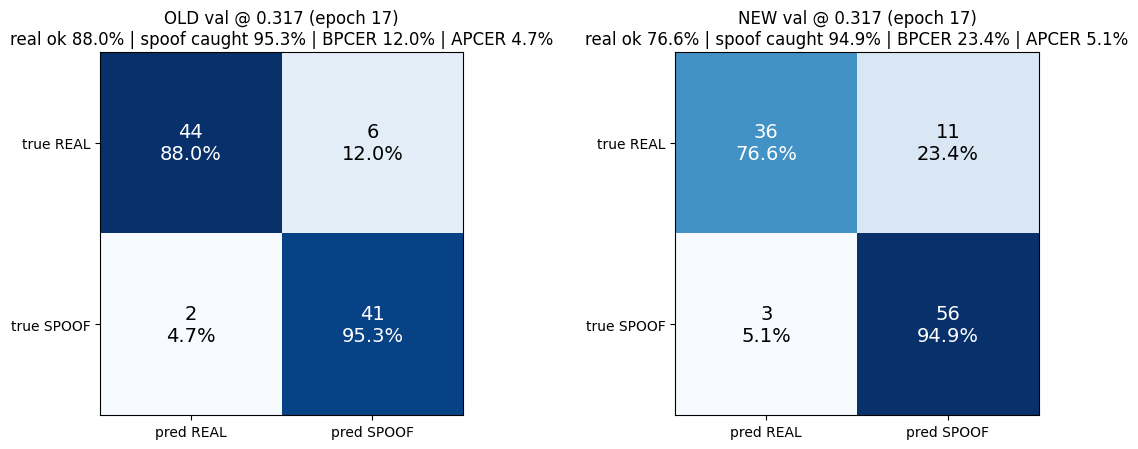

In [ ]:
new

In [ ]:
# ===== 1. DRIVE CHECK — which checkpoints exist and are they intact/loadable? =====
from google.colab import drive
drive.mount('/content/drive')
import os, json, hashlib, collections
from pathlib import Path
from datetime import datetime
import numpy as np, pandas as pd, torch

ROOT = Path("/content/drive/MyDrive/checkpoints_fullframe_moire")
assert ROOT.exists(), f"Not found: {ROOT}"

def sha16(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()[:16]

rows = []
for ck_path in sorted(ROOT.rglob("best.pth")):
    d = ck_path.parent
    r = {"run": str(d.relative_to(ROOT)), "size_KB": round(ck_path.stat().st_size / 1024, 1),
         "modified": datetime.fromtimestamp(ck_path.stat().st_mtime).strftime("%Y-%m-%d %H:%M"),
         "sha256": sha16(ck_path),
         "history.csv": (d / "history.csv").exists(), "train_summary.json": (d / "train_summary.json").exists(),
         "learning_curves.png": (d / "learning_curves.png").exists()}
    try:
        ck = torch.load(ck_path, map_location="cpu", weights_only=False)
        r.update(loadable=True, epoch=ck.get("epoch"), threshold=ck.get("threshold"),
                 p1_val_auc=ck.get("p1_val_auc", ck.get("val_auc")), p2_val_auc=ck.get("p2_val_auc"),
                 n_tensors=len(ck["state_dict"]))
    except Exception as e:
        r.update(loadable=False, error=str(e)[:80])
    rows.append(r)

CKPTS = pd.DataFrame(rows)
pd.set_option("display.width", 250); display(CKPTS)
print(f"{len(CKPTS)} checkpoints found | all loadable: {bool(CKPTS.loadable.all()) if len(CKPTS) else False}")
for d in ROOT.rglob("train_summary.json"):
    s = json.load(open(d))
    print(f"\n{d.parent.relative_to(ROOT)}:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in s.items()})


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,run,size_KB,modified,sha256,history.csv,train_summary.json,learning_curves.png,loadable,epoch,threshold,p1_val_auc,p2_val_auc,n_tensors
0,run_20261023_075249,1201.9,2026-10-23 08:00,ad919e5f4c06736a,False,False,False,True,15,NaN,0.950774,NaN,116
1,run_20261026_061459/A_baseline_s42,1202.2,2026-10-26 06:42,9da8db7d57b42b55,True,True,False,True,18,0.420095,0.938140,NaN,116
2,run_20261026_061459/B_aug_s42,1202.2,2026-10-26 06:49,cae3859ab5425b1c,True,True,False,True,28,0.468565,0.927674,NaN,116
3,run_20261026_061459/phase2_from_A_baseline_s42...,1202.5,2026-10-26 08:19,0cf451923a5d15db,True,True,True,True,17,0.317347,0.918140,0.915975,116
4,run_20261026_061459/phase2_from_A_baseline_s42...,1202.6,2026-10-27 07:25,2ee951e8bd289387,True,True,True,True,4,0.425814,0.936744,0.942731,116


5 checkpoints found | all loadable: True

run_20261026_061459/A_baseline_s42: {'run': 'A_baseline_s42', 'seed': 42, 'aug': 'none', 'best_epoch': 18, 'best_val_auc': 0.9381, 'threshold': 0.4201, 'epochs_run': 25, 'minutes': 5.0}

run_20261026_061459/B_aug_s42: {'run': 'B_aug_s42', 'seed': 42, 'aug': 'targeted', 'best_epoch': 28, 'best_val_auc': 0.9277, 'threshold': 0.4686, 'epochs_run': 30, 'minutes': 6.1}

run_20261026_061459/phase2_from_A_baseline_s42/ft_new_from_A_s42_replay0.0: {'tag': 'ft_new_from_A_s42_replay0.0', 'best_epoch': 17, 'p2_val_auc': 0.916, 'p1_val_auc': 0.9181, 'new_val_real_ok@mon': 0.8298, 'new_val_spoof_caught@mon': 0.8305, 'old_val_real_ok@mon': 0.9, 'old_val_spoof_caught@mon': 0.8372, 'threshold': 0.3173, 'epochs_run': 27, 'minutes': 5.8}

run_20261026_061459/phase2_from_A_baseline_s42/ft_v2_from_A_s42_replay0.5_real1000: {'tag': 'ft_v2_from_A_s42_replay0.5_real1000', 'best_epoch': 4, 'p2_val_auc': 0.9427, 'p2_val_auc_before': 0.93, 'p2_gain': 0.0127, 'p1_val_auc

In [ ]:
# ===== 2. MODEL DEFINITION (identical to training) + LOAD =====
import cv2, torch.nn as nn
from PIL import Image, ImageOps

# ---- pick the checkpoint (from the table above) ----
MODEL_PATH = ROOT / "run_20261026_061459/phase2_from_A_baseline_s42/ft_v3_from_A_s42_replay0.5_real900/best.pth"
# MODEL_PATH = ROOT / "run_20261026_061459/A_baseline_s42/best.pth"     # Phase 1 model, for comparison
assert MODEL_PATH.exists(), f"Not in Drive: {MODEL_PATH}"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MiniFASNetV2_Fixed(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.conv1 = self._ds(3, 8, 3, 1, 1);    self.conv2 = self._ds(8, 16, 3, 2, 1)
        self.conv3 = self._ds(16, 32, 3, 1, 1);  self.conv4 = self._ds(32, 64, 3, 2, 1)
        self.conv5 = self._ds(64, 128, 3, 1, 1); self.conv6 = self._ds(128, 256, 3, 2, 1)
        self.conv7 = self._ds(256, 256, 3, 1, 1)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1 = nn.Linear(256, 128); self.relu = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5); self.fc2 = nn.Linear(128, num_classes)
    def _ds(self, i, o, k, s, p):
        return nn.Sequential(nn.Conv2d(i, i, k, s, p, groups=i, bias=False), nn.BatchNorm2d(i), nn.ReLU(inplace=True),
                             nn.Conv2d(i, o, 1, 1, 0, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

def cbr(i, o, s): return nn.Sequential(nn.Conv2d(i, o, 3, s, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class FullFrameMoireNet(nn.Module):
    BLOCKS = ["conv1", "conv2", "conv3", "conv4", "conv5", "conv6", "conv7"]
    def __init__(self):
        super().__init__()
        self.rgb = MiniFASNetV2_Fixed()
        self.moire = nn.Sequential(cbr(1, 16, 2), cbr(16, 32, 2), cbr(32, 64, 2), cbr(64, 128, 2), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Linear(256 + 128, 128), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, 2))
    def rgb_feats(self, x):
        for b in self.BLOCKS: x = getattr(self.rgb, b)(x)
        return self.rgb.avgpool(x).flatten(1)
    def forward(self, glob, spec):
        B, N = spec.shape[:2]
        m = self.moire(spec.flatten(0, 1)).flatten(1).view(B, N, -1).mean(1)
        return self.head(torch.cat([self.rgb_feats(glob), m], 1))

ck = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
model = FullFrameMoireNet().to(DEVICE)
model.load_state_dict(ck["state_dict"], strict=True); model.eval()
cfg = ck.get("config", {"GLOBAL_SIZE": 320, "PATCH": 256, "SPEC": 128, "GRID": 3})
GLOBAL_SIZE, PATCH, SPEC, GRID = cfg["GLOBAL_SIZE"], cfg["PATCH"], cfg["SPEC"], cfg["GRID"]
THRESHOLD = float(ck.get("threshold", 0.5))
print(f"✓ loaded {MODEL_PATH.parent.name} | epoch {ck.get('epoch')} | threshold {THRESHOLD:.3f} "
      f"| OLD val AUC {ck.get('p1_val_auc', ck.get('val_auc'))} | NEW val AUC {ck.get('p2_val_auc')}")

# ---- preprocessing: EXACTLY the eval path of FullFrameMoireDS ----
def load_bgr(path):
    with Image.open(path) as im:
        return cv2.cvtColor(np.asarray(ImageOps.exif_transpose(im).convert("RGB")), cv2.COLOR_RGB2BGR)

def letterbox(img, size):
    h, w = img.shape[:2]; s = size / max(h, w)
    r = cv2.resize(img, (max(1, round(w * s)), max(1, round(h * s))), interpolation=cv2.INTER_AREA)
    c = np.zeros((size, size, 3), np.uint8); y0, x0 = (size - r.shape[0]) // 2, (size - r.shape[1]) // 2
    c[y0:y0 + r.shape[0], x0:x0 + r.shape[1]] = r
    return c

_HANN = {}
def spectrum(gray_patch):
    P = gray_patch.shape[0]
    if P not in _HANN: _HANN[P] = np.outer(np.hanning(P), np.hanning(P)).astype(np.float32)
    g = gray_patch.astype(np.float32); g -= g.mean()
    S = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g * _HANN[P]))))
    if P != SPEC: S = cv2.resize(S, (SPEC, SPEC), interpolation=cv2.INTER_AREA)
    return ((S - S.mean()) / (S.std() + 1e-6)).astype(np.float32)

def grid_patches(gray):
    h, w = gray.shape; P = min(PATCH, h, w)
    return [gray[y:y + P, x:x + P] for y in np.linspace(0, h - P, GRID).astype(int)
                                    for x in np.linspace(0, w - P, GRID).astype(int)]

def to_inputs(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    spec = np.stack([spectrum(p) for p in grid_patches(gray)])[:, None]
    g = letterbox(img_bgr, GLOBAL_SIZE).astype(np.float32) / 127.5 - 1.0
    return torch.from_numpy(g.transpose(2, 0, 1))[None], torch.from_numpy(spec)[None]

@torch.no_grad()
def predict(path, thr=None):
    thr = THRESHOLD if thr is None else thr
    g, s = to_inputs(load_bgr(path))
    p = torch.softmax(model(g.to(DEVICE), s.to(DEVICE)).float(), 1)[0, 1].item()
    return ("SPOOF" if p >= thr else "REAL"), p


AssertionError: Not in Drive: /content/drive/MyDrive/checkpoints_fullframe_moire/run_20261026_061459/phase2_from_A_baseline_s42/ft_v3_from_A_s42_replay0.5_real900/best.pth

In [ ]:
# ===== INF. Inference test for the latest fine-tuned model (ft_v3). Needs only the SETUP cell =====
MODEL_PATH = PHASE1_RUN / "phase2_from_A_baseline_s42" / "ft_v3_from_A_s42_replay0.5_real1000" / "best.pth"
SPLIT_CSV  = PHASE1_RUN / "phase2_from_A_baseline_s42" / "phase2_split.csv"
EVAL_SPLIT = "val"          # keep "val". Switch to "test" ONLY ONCE, for the final number (that is P2-6)
assert MODEL_PATH.exists(), f"Not in Drive: {MODEL_PATH}"

# ---------- 1. load model + its validation threshold ----------
ck = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=False)
sd = ck["state_dict"] if isinstance(ck, dict) and "state_dict" in ck else ck
sd = {k.removeprefix("module."): v for k, v in sd.items()}
INF_MODEL = FullFrameMoireNet().to(DEVICE)
INF_MODEL.load_state_dict(sd, strict=True); INF_MODEL.eval()
THRESHOLD = float(ck.get("threshold", 0.2283)) if isinstance(ck, dict) else 0.2283
print(f"loaded {MODEL_PATH.parent.name} | epoch {ck.get('epoch', '?')} | threshold {THRESHOLD:.4f} | sha {sha(MODEL_PATH)[:12]}")

# ---------- 2. predict on any image(s): no labels needed ----------
@torch.no_grad()
def predict_paths(paths, thr=THRESHOLD, bs=BATCH):
    """Returns DataFrame: path, p_spoof, pred ('SPOOF'/'REAL'). Same preprocessing as validation (no augmentation)."""
    paths = [str(p) for p in paths]
    dl = DataLoader(FullFrameMoireDS([(p, -1) for p in paths], False), bs, shuffle=False, num_workers=2)
    p, _, _ = predict_logits(dl, INF_MODEL)
    return pd.DataFrame({"path": paths, "p_spoof": p, "pred": np.where(p >= thr, "SPOOF", "REAL")})

def predict_folder(folder, thr=THRESHOLD):
    files = sorted(f for f in Path(folder).rglob("*") if f.suffix.lower() in EXTS)
    assert files, f"no images in {folder}"
    return predict_paths(files, thr)

def show_image(path, thr=THRESHOLD):
    r = predict_paths([path], thr).iloc[0]
    plt.figure(figsize=(4, 5)); plt.imshow(cv2.cvtColor(load_bgr(path), cv2.COLOR_BGR2RGB)); plt.axis("off")
    plt.title(f"{r.pred}  p_spoof={r.p_spoof:.3f}  (thr {thr:.3f})", color="red" if r.pred == "SPOOF" else "green")
    plt.show(); return r

# ---------- 3. labelled evaluation on the Phase 2 split ----------
df = pd.read_csv(SPLIT_CSV); df = df[df.split == EVAL_SPLIT].reset_index(drop=True)
t0 = time.time(); out = predict_paths(df.path.tolist())
df["p_spoof"] = out.p_spoof.values; y, p = df.y.values.astype(int), df.p_spoof.values
print(f"\n{EVAL_SPLIT}: {len(df)} images (real {int((y == 0).sum())}, spoof {int(y.sum())}) in {time.time() - t0:.0f}s")
print(f"ROC-AUC {roc_auc_score(y, p):.4f} | PR-AUC {average_precision_score(y, p):.4f}")

def row(name, thr):
    r = rates(y, p, thr); a, b = wilson(r["fn"], r["n_spoof"]), wilson(r["fp"], r["n_real"])
    return {"operating point": name, "thr": round(thr, 4),
            "APCER (spoof accepted)": f"{r['apcer']:.1%} ({r['fn']}/{r['n_spoof']}) [{a[0]:.0%}-{a[1]:.0%}]",
            "BPCER (real rejected)":  f"{r['bpcer']:.1%} ({r['fp']}/{r['n_real']}) [{b[0]:.0%}-{b[1]:.0%}]",
            "spoof precision": round(r["precision"], 3), "spoof recall": round(r["recall"], 3),
            "F1": round(r["f1"], 3), "bal. acc": round(r["bacc"], 3)}
ops = [("saved threshold", THRESHOLD), ("0.5 default", 0.5)]
ops += [(f"APCER<={c:.0%} (this split)", thr_for_apcer(y, p, c)) for c in (0.05, 0.10, 0.15)]
display(pd.DataFrame([row(n, t) for n, t in ops]))
print("Note: the APCER<=x rows re-pick the threshold on this split. On 'val' the saved threshold was ALSO picked here,\n"
      "so every row is slightly optimistic; only 'test' with the saved threshold gives an unbiased number.")

# confusion matrix + score histogram at the saved threshold
cm = confusion_matrix(y, (p >= THRESHOLD).astype(int), labels=[0, 1])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm): ax[0].text(j, i, f"{v}\n{v / cm[i].sum():.1%}", ha="center", va="center", fontsize=12)
ax[0].set_xticks([0, 1], ["pred REAL", "pred SPOOF"]); ax[0].set_yticks([0, 1], ["true REAL", "true SPOOF"])
ax[0].set_title(f"Confusion @ thr {THRESHOLD:.3f}")
ax[1].hist(p[y == 0], bins=30, alpha=.6, label="real"); ax[1].hist(p[y == 1], bins=30, alpha=.6, label="spoof")
ax[1].axvline(THRESHOLD, color="k", ls="--", label="threshold"); ax[1].set_xlabel("p_spoof"); ax[1].legend()
ax[1].set_title("Score distribution"); plt.tight_layout(); plt.show()

# hard slices from the label CSV (if present)
for col, lab, name in [("missed_by_shadow", 1, "spoofs missed by shadow"), ("flagged_by_prod", 0, "reals flagged by prod")]:
    if col in df:
        s = df[(df[col] == 1) & (df.y == lab)]
        if len(s):
            ok = (s.p_spoof >= THRESHOLD) == (lab == 1)
            print(f"{name}: {int(ok.sum())}/{len(s)} correct ({ok.mean():.0%})")

# per-site errors: are mistakes concentrated somewhere?
df["pred"] = (df.p_spoof >= THRESHOLD).astype(int); df["err"] = df.pred != df.y
if "site" in df:
    st = df.groupby("site").agg(n=("y", "size"), spoof=("y", "sum"), errors=("err", "sum")).query("errors > 0")
    display(st.sort_values("errors", ascending=False).head(10))

# ---------- 4. look at the mistakes ----------
def show_errors(kind="FN", k=12):
    """FN = spoof accepted as real (security risk), FP = real rejected (user friction). Most confident mistakes first."""
    e = df[(df.y == 1) & (df.pred == 0)].sort_values("p_spoof") if kind == "FN" else \
        df[(df.y == 0) & (df.pred == 1)].sort_values("p_spoof", ascending=False)
    e = e.head(k)
    if not len(e): print(f"no {kind}"); return e
    cols = 4; rows_ = math.ceil(len(e) / cols)
    plt.figure(figsize=(4 * cols, 4.4 * rows_))
    for i, r in enumerate(e.itertuples()):
        plt.subplot(rows_, cols, i + 1); plt.imshow(cv2.cvtColor(load_bgr(r.path), cv2.COLOR_BGR2RGB)); plt.axis("off")
        plt.title(f"{kind} p={r.p_spoof:.3f}\n{Path(r.path).name[:28]}", fontsize=9)
    plt.suptitle(f"{kind}: {'spoofs accepted' if kind == 'FN' else 'reals rejected'} ({len(e)} shown)"); plt.tight_layout(); plt.show()
    return e[["path", "site", "p_spoof"] if "site" in e else ["path", "p_spoof"]]

display(show_errors("FN")); display(show_errors("FP"))
df.to_csv(MODEL_PATH.parent / f"inference_{EVAL_SPLIT}.csv", index=False)
print("saved per-image scores ->", MODEL_PATH.parent / f"inference_{EVAL_SPLIT}.csv")

NameError: name 'PHASE1_RUN' is not defined

In [ ]:
show_image("/content/drive/MyDrive/some_checkin.jpg")                 # one image, with picture + verdict
res = predict_folder("/content/drive/MyDrive/new_batch"); display(res) # whole folder -> table
res.pred.value_counts()
predict_folder("/content/drive/MyDrive/new_batch", thr=0.40)           # try a looser operating point